#**Block 1: Loading the Dataset**

##**Importing Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

##**Reading the Data**

In [ ]:
df = pd.read_csv("/content/No_Chrun_DataSet.csv")

#**Block 2: Basic Checks and Data Cleaning**

In [ ]:
df

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,BSNL,F,19,Tamil Nadu,Delhi,326273,2020-01-05,0,81532,29,36,3952,0
996,997,Airtel,M,38,Nagaland,Kolkata,126707,2020-01-05,4,127367,39,19,5328,0
997,998,Vodafone,M,18,Odisha,Chennai,742600,2020-01-05,1,120764,49,42,6260,1
998,999,Vodafone,M,64,Tripura,Delhi,186458,2020-01-05,1,95036,96,12,2262,0


Note:
* `customer_id` and `pincode` are identifiers. I make `customer_id` the index and drop `pincode` later.
* `churn` is the target column. According to the project guideline, we need to create another feature later in the project, called Churn Flag.
* The date of registration should be separated into three different columns, one each for day, month and year.

In [ ]:
df.shape

(1000, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           1000 non-null   int64 
 1   telecom_partner       1000 non-null   object
 2   gender                1000 non-null   object
 3   age                   1000 non-null   int64 
 4   state                 1000 non-null   object
 5   city                  1000 non-null   object
 6   pincode               1000 non-null   int64 
 7   date_of_registration  1000 non-null   object
 8   num_dependents        1000 non-null   int64 
 9   estimated_salary      1000 non-null   int64 
 10  calls_made            1000 non-null   int64 
 11  sms_sent              1000 non-null   int64 
 12  data_used             1000 non-null   int64 
 13  churn                 1000 non-null   int64 
dtypes: int64(9), object(5)
memory usage: 109.5+ KB


Note:
* Data types: Nine columns are numeric and five are stored as text (`telecom_partner`, `gender`, `state`, `city` and `date_of_registration`). `date_of_registration` is stored as text rather than as a date. Everything else is typed correctly.

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df.isna().sum())

customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64


Note:
* Missing values: There are none, in any column. We do not need any missing-value handling before analysis.
* Duplicates: There are no duplicate rows.

In [ ]:
print(df.describe().T)

                   count        mean            std       min        25%  \
customer_id       1000.0     500.500     288.819436       1.0     250.75   
age               1000.0      45.400      16.390077      18.0      31.00   
pincode           1000.0  555700.688  257620.890154  100027.0  334693.75   
num_dependents    1000.0       1.937       1.402497       0.0       1.00   
estimated_salary  1000.0   84397.693   36449.528961   20038.0   52110.75   
calls_made        1000.0      48.846      29.326069     -10.0      25.00   
sms_sent          1000.0      24.512      14.849120      -4.0      12.00   
data_used         1000.0    4826.720    2955.244989    -884.0    2412.75   
churn             1000.0       0.179       0.383544       0.0       0.00   

                       50%        75%       max  
customer_id          500.5     750.25    1000.0  
age                   45.0      60.00      74.0  
pincode           558293.5  779263.75  999941.0  
num_dependents         2.0       3.00  

Note:
* Summary statistics: Ages run from 18 to 74 (average 45), and salaries run from about 20k to 150k (average about 84k). The minimums for `calls_made` (-10), `sms_sent` (-4) and `data_used` (-884) are negative, which is the first sign of bad data.
* Negative values do not make sense for these columns. I therefore treat them as errors and impute them with zero, the mean, the median or the mode, depending on the nature of the column. I use the median in this project.

In [ ]:
usage_cols = ["calls_made", "sms_sent", "data_used"]
for c in usage_cols:
    print(f"{c}: negative = {(df[c] < 0).sum()}, zero = {(df[c] == 0).sum()}")

calls_made: negative = 29, zero = 5
sms_sent: negative = 27, zero = 10
data_used: negative = 35, zero = 0


Note:
* Invalid values: 29 rows have negative calls, 27 have negative SMS and 35 have negative data usage. That is roughly 3% of rows per column, and usage cannot be below zero, so these are errors. There are also 5 zero-call and 10 zero-SMS customers, which look like genuine inactive users.

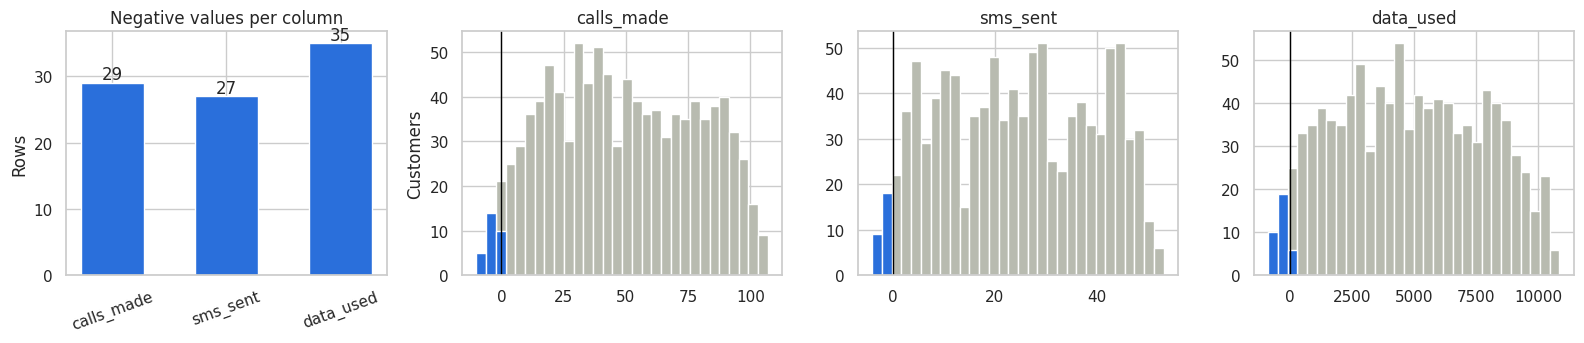

In [ ]:
# (V1 addition) Visual: where the negative usage values sit
V1_ACCENT, V1_GREY = "#2a6fdb", "#b8bbb0"                    # one accent + one quiet grey, reused by every added chart
V1_SERIES = ["#2a6fdb", "#5f6368", "#d9822b"]                # only used when a chart needs 3 distinguishable lines

neg_counts = pd.Series({c: int((df[c] < 0).sum()) for c in usage_cols})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].bar(neg_counts.index, neg_counts.values, color=V1_ACCENT, width=0.55)
axes[0].set_title("Negative values per column"); axes[0].set_ylabel("Rows")
for i, v in enumerate(neg_counts.values):
    axes[0].text(i, v + 0.5, str(v), ha="center")
axes[0].tick_params(axis="x", labelrotation=20)

for ax, c in zip(axes[1:], usage_cols):
    bins = np.histogram_bin_edges(df[c], bins=30)
    ax.hist(df[c], bins=bins, color=V1_GREY, edgecolor="white")
    ax.hist(df.loc[df[c] < 0, c], bins=bins, color=V1_ACCENT, edgecolor="white")   # negatives highlighted
    ax.axvline(0, color="black", lw=1)
    ax.set_title(c)
axes[1].set_ylabel("Customers")
plt.tight_layout(); plt.show()

Note:
* The negative values form a small cluster at the left edge of each usage histogram (highlighted in blue), not a long tail: 29 in `calls_made`, 27 in `sms_sent` and 35 in `data_used`. Everything else in each distribution starts at or just above zero, which fits the view that these are entry errors. I therefore judge that filling them with the median is safer than dropping the rows.

In [ ]:
num_cols = ["age", "estimated_salary", "calls_made", "sms_sent", "data_used"]
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {outliers} outliers")

age: 0 outliers
estimated_salary: 0 outliers
calls_made: 0 outliers
sms_sent: 0 outliers
data_used: 0 outliers


Note:
* Outliers: There are no outliers in any numeric column. The IQR method does not catch the negative values because they sit inside its fences, so I handle the negatives separately from outliers.

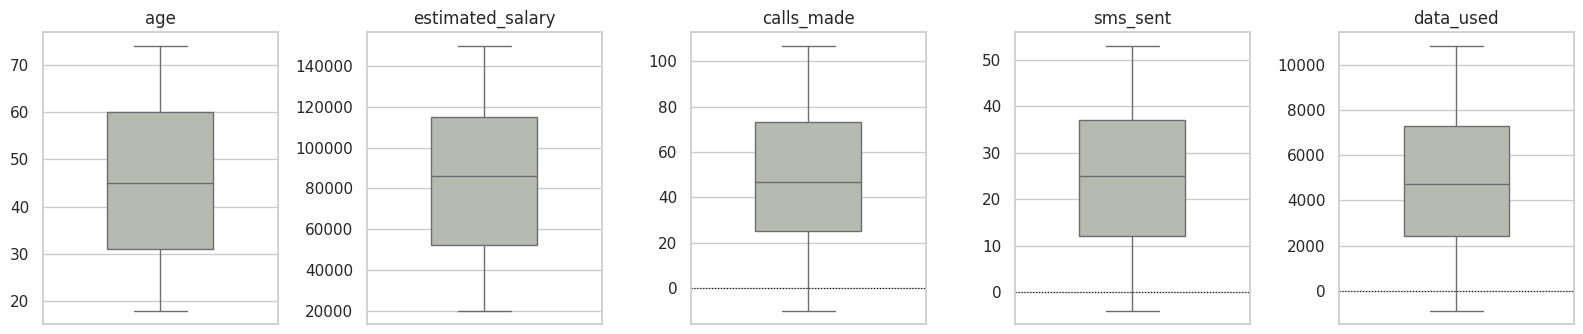

In [ ]:
# (V1 addition) Visual: box plots for the outlier check
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color=V1_GREY, width=0.45, fliersize=3)
    if c in usage_cols:
        ax.axhline(0, color="black", lw=0.8, ls=":")          # usage can never go below this line
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Note:
* No point lies beyond the whiskers in any of the five box plots, which matches the IQR check. The dotted line marks zero. The lower whiskers of `calls_made`, `sms_sent` and `data_used` dip below it, which is the negative-value problem showing up again. The boxes are close to symmetric around their medians.

In [ ]:
for c in ["telecom_partner", "gender", "state", "city", "num_dependents", "churn"]:
    print(f"\n{c} ({df[c].nunique()} unique values)")
    print(df[c].value_counts())


telecom_partner (4 unique values)
telecom_partner
Vodafone        261
Reliance Jio    252
BSNL            248
Airtel          239
Name: count, dtype: int64

gender (2 unique values)
gender
M    611
F    389
Name: count, dtype: int64

state (28 unique values)
state
Himachal Pradesh     50
Gujarat              44
Haryana              44
Assam                43
Arunachal Pradesh    42
Tamil Nadu           42
Kerala               41
Bihar                41
Telangana            39
Uttar Pradesh        39
Karnataka            38
Nagaland             38
Andhra Pradesh       38
Maharashtra          37
Mizoram              36
Manipur              34
West Bengal          34
Jharkhand            33
Uttarakhand          32
Odisha               32
Madhya Pradesh       32
Chhattisgarh         30
Punjab               29
Rajasthan            29
Sikkim               29
Meghalaya            28
Tripura              25
Goa                  21
Name: count, dtype: int64

city (6 unique values)
city
Mumbai 

Note:

Categorical columns:
* The four telecom partners are balanced (Vodafone 261, Jio 252, BSNL 248, Airtel 239).
* Gender is skewed, with 611 male and 389 female customers.
* There are 28 states, with Himachal Pradesh the largest (50 customers).
* The six cities each have 154 to 174 customers.
* Dependents (0 to 4) are spread almost evenly, at about 200 each.

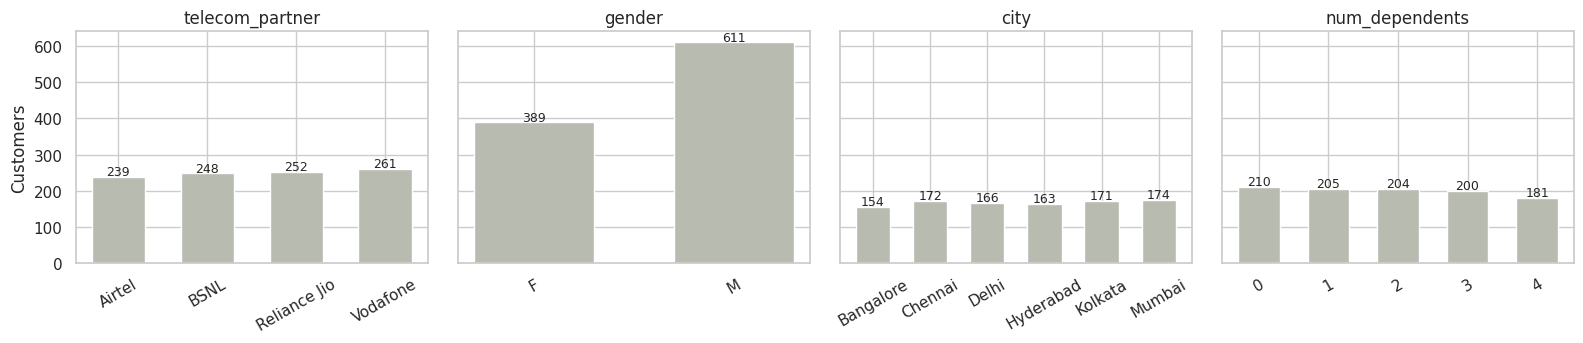

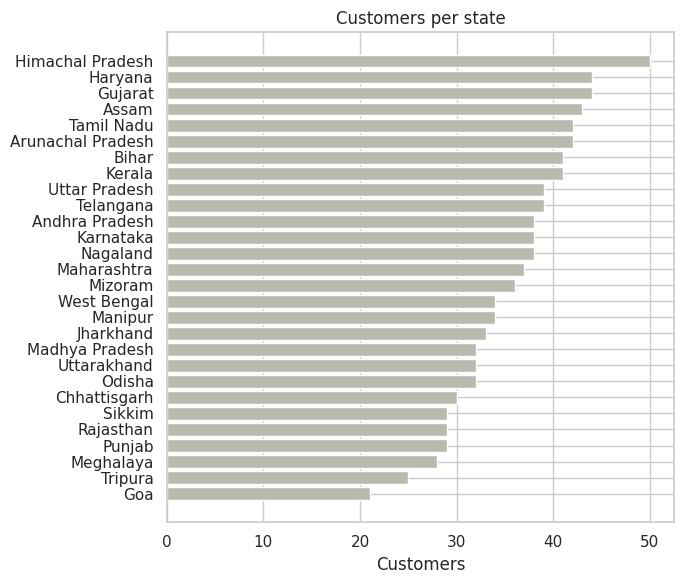

In [ ]:
# (V1 addition) Visual: how customers are spread across the categorical columns
cat_cols_v1 = ["telecom_partner", "gender", "city", "num_dependents"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, c in zip(axes, cat_cols_v1):
    counts = df[c].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=V1_GREY, width=0.6)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 5, str(v), ha="center", fontsize=9)
    ax.set_title(c); ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("Customers")
plt.tight_layout(); plt.show()

# State has 28 values, so a horizontal bar sorted by size
state_counts = df["state"].value_counts().sort_values()
plt.figure(figsize=(7, 6))
plt.barh(state_counts.index.astype(str), state_counts.values, color=V1_GREY)
plt.xlabel("Customers"); plt.title("Customers per state")
plt.tight_layout(); plt.show()

Note:
* Partner (239 to 261 customers), city (154 to 174) and dependents (181 to 210) are spread almost evenly, while gender leans male (611 vs 389).
* The 28 states range from only 21 customers (Goa) to 50 (Himachal Pradesh). Any state-level churn rate therefore rests on a few dozen customers, which is why `state` is dropped later.

In [ ]:
for c in ["telecom_partner", "gender", "state", "city"]:
    s = df[c].astype(str)
    print(c,
          "| whitespace issues:", (s != s.str.strip()).sum(),
          "| case variants:", s.str.lower().str.strip().nunique() - s.nunique())

telecom_partner | whitespace issues: 0 | case variants: 0
gender | whitespace issues: 0 | case variants: 0
state | whitespace issues: 0 | case variants: 0
city | whitespace issues: 0 | case variants: 0


Note:
* Whitespace and case: There are no problems. Labels are consistent, so no text cleaning is needed.

In [ ]:
dates = pd.to_datetime(df["date_of_registration"], errors="coerce")
print("Unparseable dates:", dates.isna().sum())
print("Range:", dates.min(), "to", dates.max())

Unparseable dates: 0
Range: 2020-01-01 00:00:00 to 2020-01-06 00:00:00


Note:
* Date column: All dates parse, but registrations cover only 6 days (1 to 6 January 2020). Customer tenure cannot be calculated from this, so the column is of little use as a predictor.

In [ ]:
print(df["pincode"].astype(str).str.len().value_counts())

pincode
6    1000
Name: count, dtype: int64


Note:
* Pincode: All 1,000 pincodes are valid 6-digit numbers. They are identifiers rather than useful features, so they are excluded from modelling.

In [ ]:
print("Cities appearing in more than one state:",
      (df.groupby("city")["state"].nunique() > 1).sum())

Cities appearing in more than one state: 6


Note:
* City vs state: All 6 cities appear under multiple states (for example, one city is linked to many states), which is not realistic. I therefore treat `state` and `city` as unreliable for location-based conclusions.

In [ ]:
print(df["churn"].value_counts(normalize=True).round(3))

churn
0    0.821
1    0.179
Name: proportion, dtype: float64


Note:
* Churn balance: 82.1% of customers stayed and 17.9% churned (179 customers). That is above the 10% churn rate in the spec, and the classes are imbalanced enough that accuracy alone would be misleading. A model that predicts "stay" for everyone would score 82% accuracy while catching no churners.

Overall, the data is structurally clean. The main issues I found are the negative usage values, unreliable location columns, a near-useless date column and the class imbalance.

##**Applying Necessary Data Cleaning Methods**

In [ ]:
# Step 1: fix data types
df["date_of_registration"] = pd.to_datetime(df["date_of_registration"])
for c in ["telecom_partner", "gender", "state", "city"]:
    df[c] = df[c].astype("category")

# Step 2: replace negative usage values with the column median
for c in usage_cols:
    df.loc[df[c] < 0, c] = np.nan      # mark invalid values as missing
    df[c] = df[c].fillna(df[c].median())   # fill them with the median

# Step 3: use customer_id as the index and drop pincode
df = df.set_index("customer_id")
df = df.drop(columns=["pincode"])

# Verify
print(df.shape)                                  # (1000, 12)
print("Nulls:", df.isna().sum().sum())           # 0
print("Negatives left:", (df[usage_cols] < 0).sum().sum())   # 0

(1000, 12)
Nulls: 0
Negatives left: 0


Note:

* Data types: `date_of_registration` is now a real datetime, and the four text columns are categories. This saves memory and makes grouping and encoding easier later.
* Negative values: 29 values in `calls_made`, 27 in `sms_sent` and 35 in `data_used` were replaced with the column medians (49 calls, 25 SMS, 4,897 MB). I used the median because it is not pulled around by extreme values, and I left zeros alone because they look like genuine inactive customers. The usage columns are now stored as floats, which is harmless. The minimum values are now 0, 0 and 14, with no negatives.
* Index and pincode: `customer_id` is now the row index (all 1,000 are unique), so it will not be mistaken for a feature. I dropped `pincode` because it is an identifier and not a predictor.

Result: `df` is now 1,000 rows by 12 columns, with zero nulls and zero negatives. The churn rate is unchanged at 17.9%, so cleaning did not distort the target.

Note:
* I hold back the cleaning of the location columns and `date_of_registration` for now and deal with them later.

#**Block 3: Exploratory Data Analysis**

In [ ]:
from scipy import stats

num = ["age", "estimated_salary", "calls_made", "sms_sent", "data_used"]
ACCENT = "#2a6fdb"   # one color for all single-series charts

churn
0    821
1    179
Name: count, dtype: int64
0.179


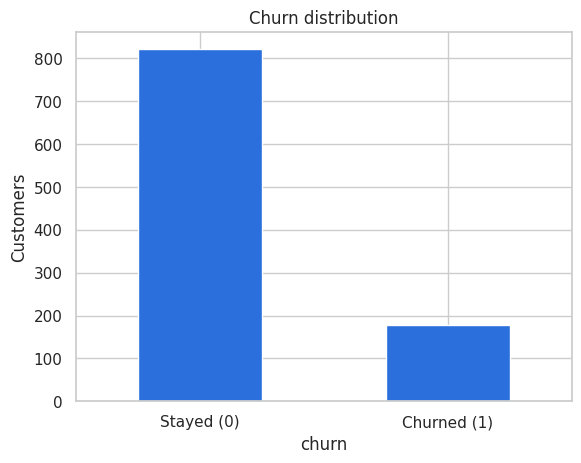

In [ ]:
# Target distribution
print(df["churn"].value_counts())
print(df["churn"].mean().round(3))

ax = df["churn"].value_counts().sort_index().plot(kind="bar", color=ACCENT, width=0.5)
ax.set_xticklabels(["Stayed (0)", "Churned (1)"], rotation=0)
ax.set_ylabel("Customers"); ax.set_title("Churn distribution")
plt.show()

Note:
* 821 customers stayed and 179 churned, a churn rate of 17.9%. That is well above the 10% quoted in the spec, so the business problem is real, but it also means the classes are imbalanced (about 4.6 stayers per churner). Any accuracy figure above 82% only reflects this imbalance, so we will judge models on recall, precision and ROC-AUC.

                      mean   median       std  skew
age                  45.40     45.0     16.39  0.05
estimated_salary  84397.69  85930.0  36449.53 -0.04
calls_made           50.38     49.0     27.86  0.11
sms_sent             25.25     25.0     14.17  0.02
data_used          5011.17   4897.0   2783.93  0.10


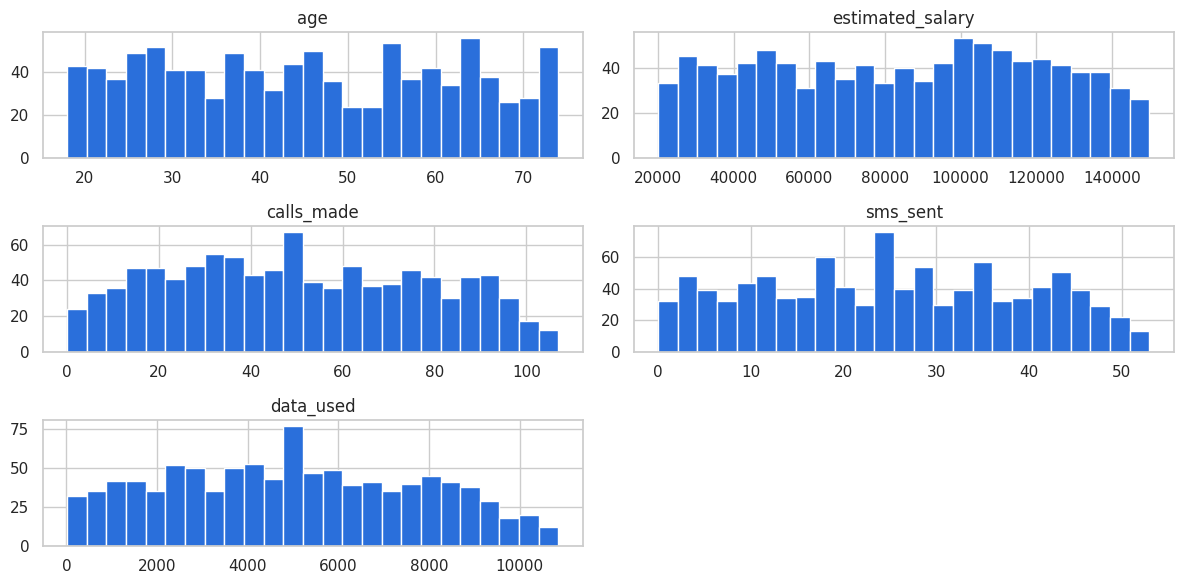

In [ ]:
# Distribution of numeric columns
print(df[num].agg(["mean", "median", "std", "skew"]).round(2).T)

df[num].hist(bins=25, figsize=(12, 6), color=ACCENT, edgecolor="white")
plt.tight_layout(); plt.show()

Note:
* Means and medians are almost identical in every column (age 45.4 vs 45, calls 50.4 vs 49), and skewness is close to 0 (between -0.04 and 0.11).
* The columns are symmetric with no heavy tails, which is why the earlier outlier check found nothing. I therefore apply no log transforms or outlier treatment, and I leave scaling until modelling.
* Values are also spread evenly across their range, which is more typical of generated data than of real customer behaviour.

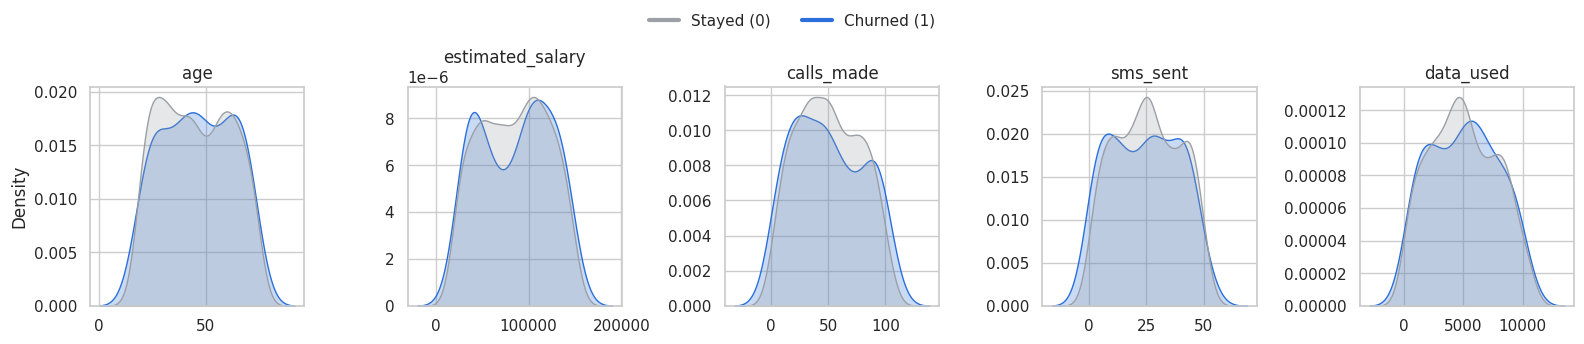

In [ ]:
# (V1 addition) Visual: do churners and stayers have different distributions?
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, c in zip(axes, num):
    sns.kdeplot(data=df, x=c, hue="churn", common_norm=False, fill=True, alpha=0.25, ax=ax,
                palette={0: "#9aa0a6", 1: ACCENT}, legend=False, warn_singular=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
axes[0].set_ylabel("Density")
fig.legend(handles=[plt.Line2D([0], [0], color="#9aa0a6", lw=3, label="Stayed (0)"),
                    plt.Line2D([0], [0], color=ACCENT, lw=3, label="Churned (1)")],
           loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

Note:
* The churner and stayer curves overlap almost completely in all five columns. The small differences (for example, stayers peak slightly higher near 25 SMS and around 40 calls) are about the size of the sampling noise expected from a group of 179 churners, in line with the non-significant tests shown below.


telecom_partner  (chi-square p = 0.350)
                  mean  count
telecom_partner              
Airtel           0.176    239
BSNL             0.165    248
Reliance Jio     0.159    252
Vodafone         0.215    261

gender  (chi-square p = 0.848)
         mean  count
gender              
F       0.175    389
M       0.182    611

city  (chi-square p = 0.637)
            mean  count
city                   
Bangalore  0.182    154
Chennai    0.180    172
Delhi      0.151    166
Hyderabad  0.153    163
Kolkata    0.216    171
Mumbai     0.190    174

num_dependents  (chi-square p = 0.840)
                 mean  count
num_dependents              
0               0.162    210
1               0.195    205
2               0.196    204
3               0.175    200
4               0.166    181


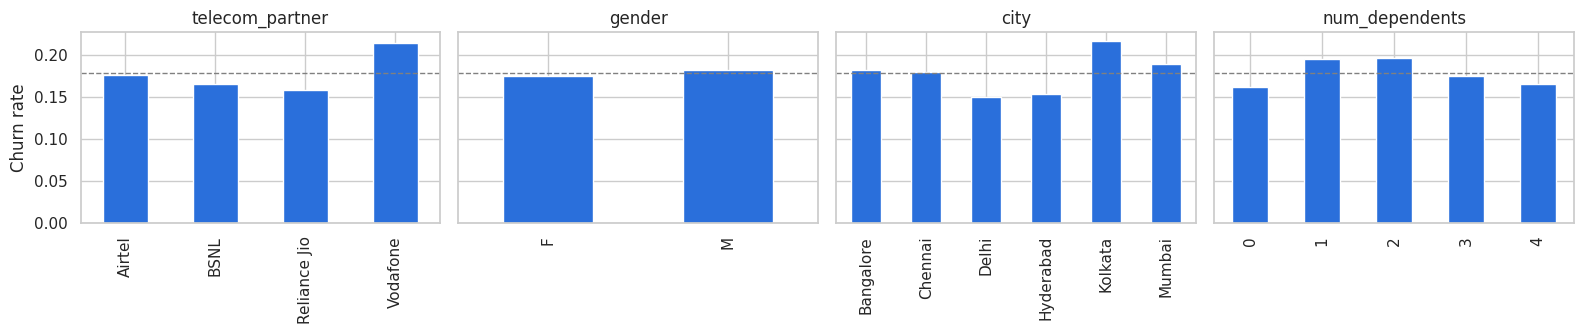

In [ ]:
# Churn rate by category
for c in ["telecom_partner", "gender", "city", "num_dependents"]:
    rates = df.groupby(c, observed=True)["churn"].agg(["mean", "count"]).round(3)
    p = stats.chi2_contingency(pd.crosstab(df[c], df["churn"]))[1]
    print(f"\n{c}  (chi-square p = {p:.3f})\n{rates}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, c in zip(axes, ["telecom_partner", "gender", "city", "num_dependents"]):
    df.groupby(c, observed=True)["churn"].mean().plot(kind="bar", ax=ax, color=ACCENT)
    ax.axhline(df["churn"].mean(), color="grey", ls="--", lw=1)   # overall average
    ax.set_title(c); ax.set_xlabel("")
axes[0].set_ylabel("Churn rate")
plt.tight_layout(); plt.show()

Note:

No category is significantly linked to churn (all p-values above 0.05).

* Partner: Vodafone is highest at 21.5% (261 customers) and Jio lowest at 15.9%. That is the biggest gap, but p = 0.35 means it could be chance.
* City: Kolkata is highest at 21.6%, and Delhi and Hyderabad are lowest at about 15%. p = 0.64.
* Gender: 17.5% for women vs 18.2% for men (p = 0.85).
* Dependents: 16% to 20% across all values, with no trend (p = 0.84).

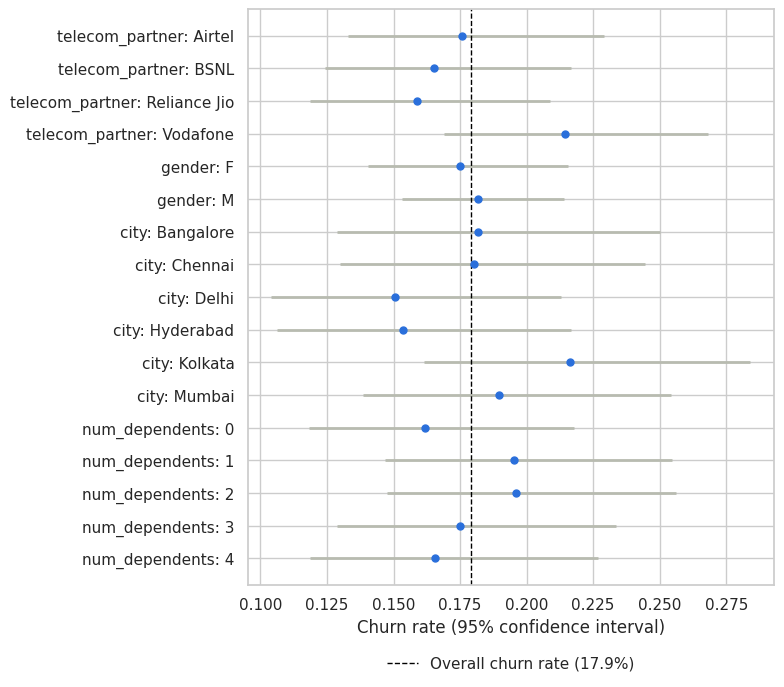

Groups whose 95% interval excludes the overall rate: 0 of 17


In [ ]:
# (V1 addition) Visual: churn rate per group with 95% confidence intervals
def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

base_rate = df["churn"].mean()
groups = []
for c in ["telecom_partner", "gender", "city", "num_dependents"]:
    for level, g in df.groupby(c, observed=True)["churn"]:
        lo, hi = wilson_ci(g.sum(), len(g))
        groups.append((f"{c}: {level}", g.mean(), lo, hi))
ci = pd.DataFrame(groups, columns=["group", "rate", "lo", "hi"])[::-1].reset_index(drop=True)

plt.figure(figsize=(8, 7))
plt.hlines(ci.index, ci["lo"], ci["hi"], color=V1_GREY, lw=2)
plt.scatter(ci["rate"], ci.index, color=ACCENT, zorder=3, s=25)
plt.axvline(base_rate, color="black", ls="--", lw=1, label=f"Overall churn rate ({base_rate:.1%})")
plt.yticks(ci.index, ci["group"]); plt.xlabel("Churn rate (95% confidence interval)")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

outside = int(((ci["lo"] > base_rate) | (ci["hi"] < base_rate)).sum())
print("Groups whose 95% interval excludes the overall rate:", outside, "of", len(ci))

Note:
* All 17 groups have a 95% interval that contains the overall churn rate of 17.9% (the printed count of groups that exclude it is 0 of 17). The intervals are wide, roughly ±3 to ±6 points, because each group holds only 154 to 611 customers.
* The two biggest gaps, Vodafone (21.5%) and Kolkata (21.6%), are still well inside the noise. Differences of this size between groups of this size cannot be told apart from chance.

churn                          0        1
age              mean       45.2     46.1
                 median     44.0     46.0
estimated_salary mean    84225.7  85186.3
                 median  84945.0  90749.0
calls_made       mean       50.5     50.0
                 median     49.0     49.0
sms_sent         mean       25.5     24.1
                 median     25.0     25.0
data_used        mean     5005.7   5036.1
                 median   4897.0   4897.0
age: t-test p = 0.539 | Mann-Whitney p = 0.524
estimated_salary: t-test p = 0.758 | Mann-Whitney p = 0.717
calls_made: t-test p = 0.833 | Mann-Whitney p = 0.711
sms_sent: t-test p = 0.272 | Mann-Whitney p = 0.249
data_used: t-test p = 0.897 | Mann-Whitney p = 0.854


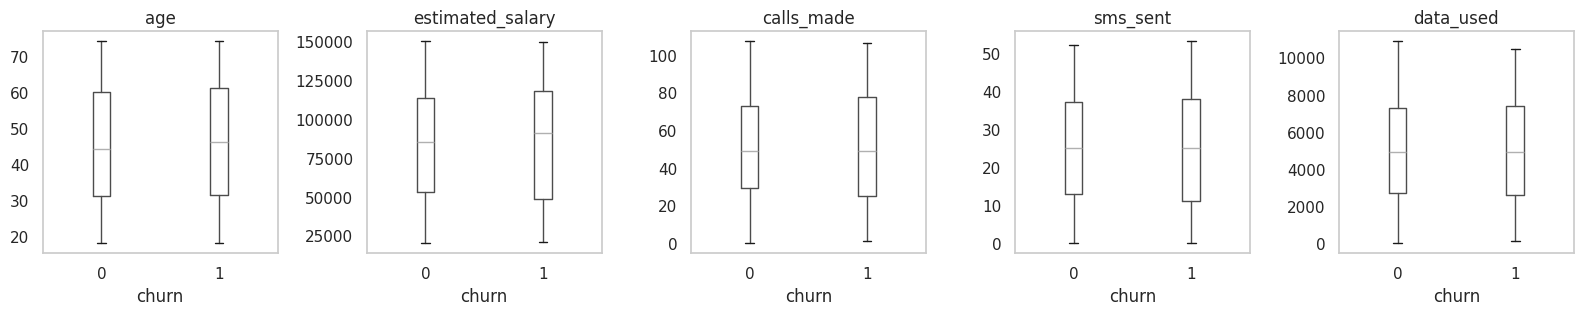

In [ ]:
# Numerical columns, churners vs stayers
print(df.groupby("churn")[num].agg(["mean", "median"]).round(1).T)

for c in num:
    a, b = df.loc[df.churn == 0, c], df.loc[df.churn == 1, c]
    print(f"{c}: t-test p = {stats.ttest_ind(a, b, equal_var=False)[1]:.3f}"
          f" | Mann-Whitney p = {stats.mannwhitneyu(a, b)[1]:.3f}")

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, c in zip(axes, num):
    df.boxplot(column=c, by="churn", ax=ax, grid=False)
    ax.set_title(c); ax.set_xlabel("churn")
plt.suptitle(""); plt.tight_layout(); plt.show()

Note:
* The two groups are practically indistinguishable. Mean calls are 50.5 vs 50.0, mean data used is 5,006 vs 5,036 MB, and mean age is 45.2 vs 46.1. All p-values are between 0.25 and 0.90 under both the t-test and the rank-based Mann-Whitney test, so the result does not depend on the distribution shape. The one small hint is the median salary (about 84.9k for stayers vs 90.7k for churners), but the test says that it is not significant (p = 0.72).

                   age  estimated_salary  calls_made  sms_sent  data_used  \
age               1.00             -0.04       -0.04      0.01      -0.01   
estimated_salary -0.04              1.00       -0.03      0.01      -0.03   
calls_made       -0.04             -0.03        1.00     -0.02      -0.02   
sms_sent          0.01              0.01       -0.02      1.00       0.01   
data_used        -0.01             -0.03       -0.02      0.01       1.00   
num_dependents   -0.02             -0.02       -0.04      0.01      -0.00   
churn             0.02              0.01       -0.01     -0.04       0.00   

                  num_dependents  churn  
age                        -0.02   0.02  
estimated_salary           -0.02   0.01  
calls_made                 -0.04  -0.01  
sms_sent                    0.01  -0.04  
data_used                  -0.00   0.00  
num_dependents              1.00  -0.00  
churn                      -0.00   1.00  


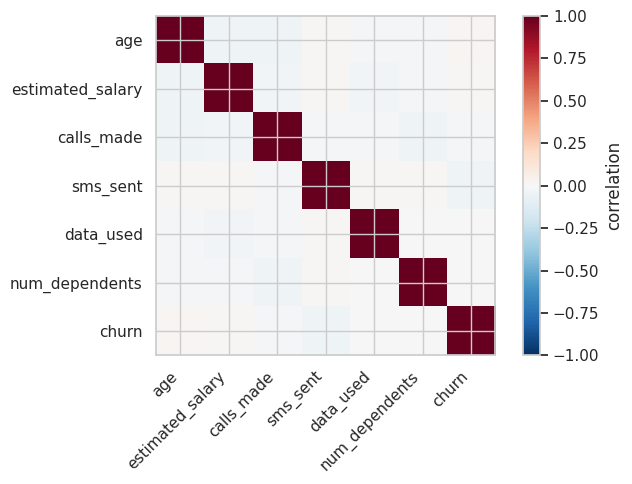

In [ ]:
# Correlation matrix
corr = df[num + ["num_dependents", "churn"]].corr().round(2)
print(corr)

plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.tight_layout(); plt.show()

Note:
* Every feature's correlation with churn is between -0.04 and +0.02, which is effectively zero. The strongest is `sms_sent` at -0.04, meaning that slightly more SMS goes with slightly less churn, which is far too small to matter. The features are also uncorrelated with each other (all within ±0.04), so there is no multicollinearity, but also no hidden relationships to exploit. The matrix is almost uniformly pale.

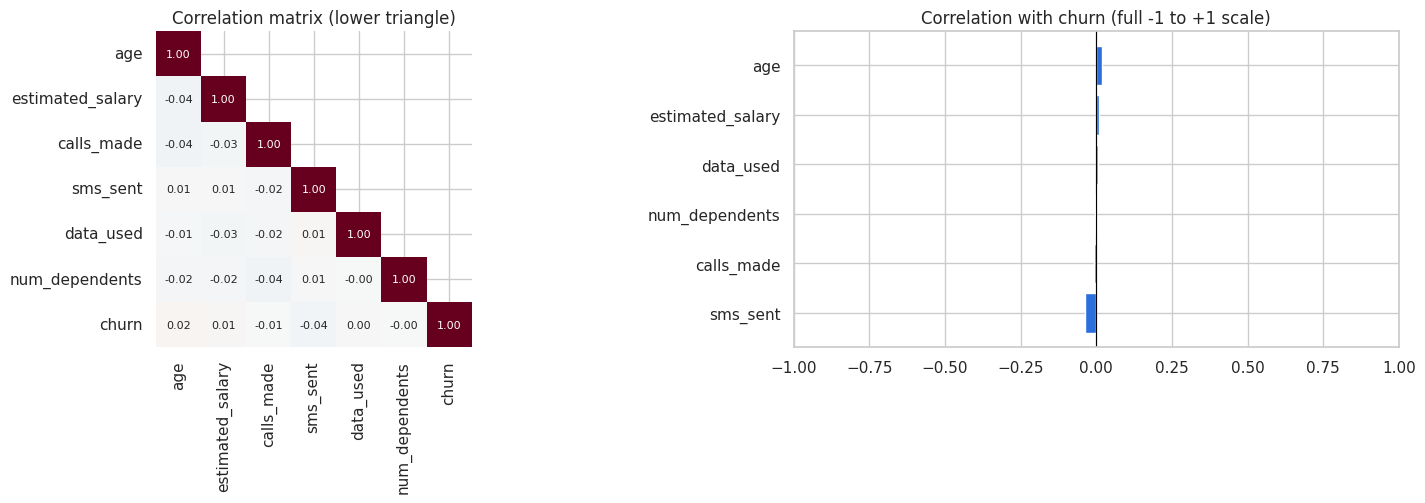

In [ ]:
# (V1 addition) Visual: annotated correlation heatmap + each feature's correlation with churn
corr_v1 = df[num + ["num_dependents", "churn"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})

mask = np.triu(np.ones_like(corr_v1, dtype=bool), k=1)
sns.heatmap(corr_v1, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, cbar=False, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("Correlation matrix (lower triangle)")

with_churn = corr_v1["churn"].drop("churn").sort_values()
axes[1].barh(with_churn.index, with_churn.values, color=ACCENT)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlim(-1, 1)                                       # full -1 to +1 scale, so small values look small
axes[1].set_title("Correlation with churn (full -1 to +1 scale)")
plt.tight_layout(); plt.show()

Note:
* The heatmap is almost uniformly pale: every off-diagonal value lies between -0.04 and +0.02. On the right, the correlation with churn is drawn on the full -1 to +1 scale so that it cannot be exaggerated. The largest bar, `sms_sent` at -0.04, is barely visible. These are the same numbers as in the earlier matrix, drawn in a way that shows how close to zero they are.

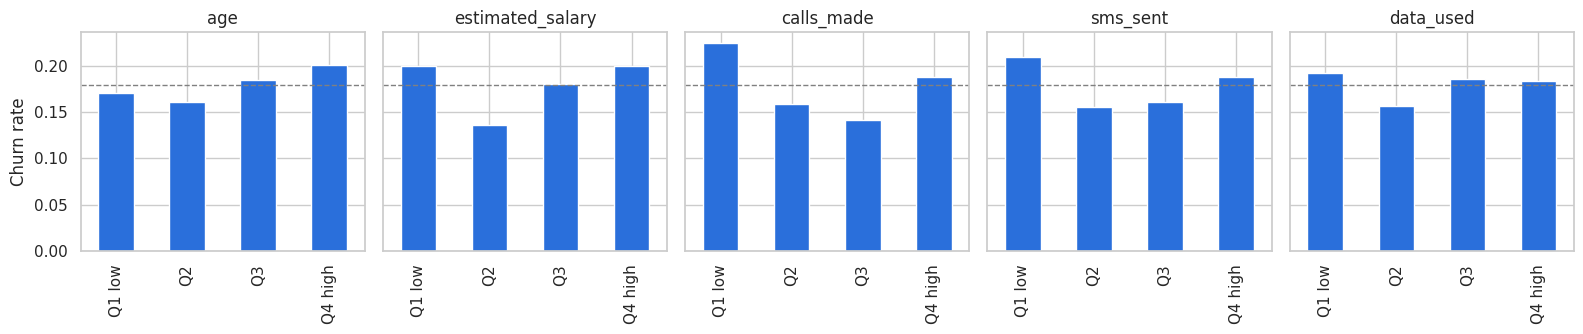

In [ ]:
# Churn rate by quartile (looking for non-linear patterns)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), sharey=True)
for ax, c in zip(axes, num):
    q = pd.qcut(df[c], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    df.groupby(q, observed=True)["churn"].mean().plot(kind="bar", ax=ax, color=ACCENT)
    ax.axhline(df["churn"].mean(), color="grey", ls="--", lw=1)
    ax.set_title(c); ax.set_xlabel("")
axes[0].set_ylabel("Churn rate")
plt.tight_layout(); plt.show()

Note:
* This is the only place where any structure appears. Calls and SMS both show a faint U-shape: the lowest-usage quartile churns most (22.5% for calls, 21.0% for SMS), the middle quartiles least (about 14% to 16%), and the top quartile rises again (about 19%). Salary has a similar shape (13.6% in Q2 vs 20% at both extremes), and age rises gently, with the oldest quartile at 20.1%. These patterns could matter for tree-based models, which can pick up non-linear patterns that correlations miss. However, with 5 variables × 4 bins, some gaps of this size will appear by chance, so I treat them as hypotheses to test in modelling, not as conclusions.

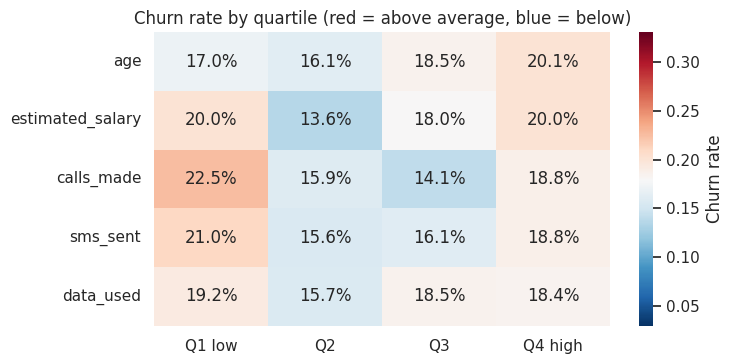

In [ ]:
# (V1 addition) Visual: churn rate by quartile as one heatmap, centred on the overall churn rate
q_tbl = pd.DataFrame({c: df.groupby(pd.qcut(df[c], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"]), observed=True)["churn"].mean()
                      for c in num}).T
plt.figure(figsize=(7.5, 3.8))
sns.heatmap(q_tbl, annot=True, fmt=".1%", cmap="RdBu_r", center=df["churn"].mean(),
            vmin=0.03, vmax=0.33, cbar_kws={"label": "Churn rate"})
plt.title("Churn rate by quartile (red = above average, blue = below)")
plt.ylabel(""); plt.tight_layout(); plt.show()

Note:
* This is the same information as the quartile bars, in one grid. The two most extreme cells are `calls_made` Q1 (22.5%, red) and `estimated_salary` Q2 (13.6%, blue), about 9 points apart, with roughly 250 customers in each cell.
* `sms_sent` repeats the low-usage-churns-more shape of `calls_made` (21.0% in Q1), and churn rises with age from 16.1% (Q2) to 20.1% (Q4).
* With 20 cells, a few will look extreme by chance. I treat the grid as a pointer for the tree models to check, not as evidence.

In [ ]:
# Registration date
print(df.groupby(df["date_of_registration"].dt.date)["churn"].agg(["mean", "count"]).round(3))

                       mean  count
date_of_registration              
2020-01-01            0.170    200
2020-01-02            0.150    200
2020-01-03            0.185    200
2020-01-04            0.180    200
2020-01-05            0.211    199
2020-01-06            0.000      1


Note:
* 200 customers registered on each of 1 to 4 January 2020, 199 on 5 January and just one on 6 January. A perfectly even 200 per day is not how real registrations behave, which supports the view that the data is synthetic. Churn ranges from 15% to 21% across the first five days, with no meaningful trend. This column has almost no predictive value, so I drop it at feature selection.

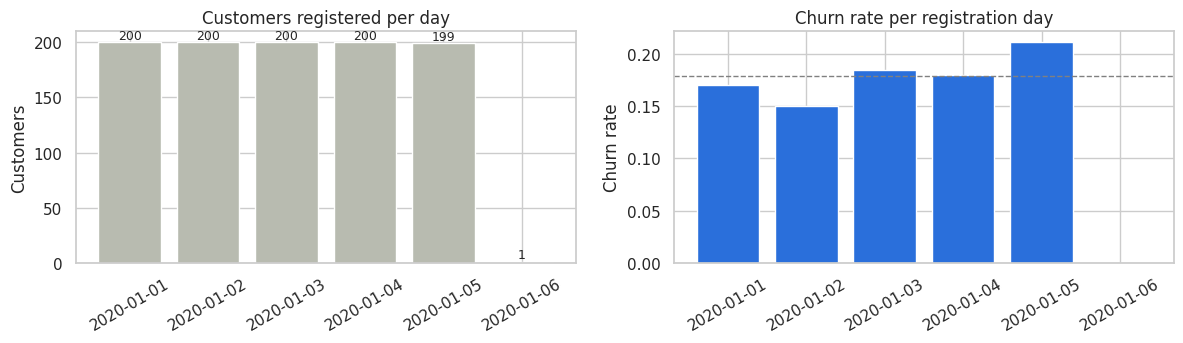

In [ ]:
# (V1 addition) Visual: registrations and churn rate per registration day
by_day = df.groupby(df["date_of_registration"].dt.date)["churn"].agg(["mean", "count"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(by_day.index.astype(str), by_day["count"], color=V1_GREY)
for i, n_ in enumerate(by_day["count"]):
    axes[0].text(i, n_ + 3, str(n_), ha="center", fontsize=9)           # the 6 Jan bar is too short to see: its label is the point
axes[0].set_title("Customers registered per day"); axes[0].set_ylabel("Customers")
axes[1].bar(by_day.index.astype(str), by_day["mean"], color=ACCENT)
axes[1].axhline(df["churn"].mean(), color="grey", ls="--", lw=1)
axes[1].set_title("Churn rate per registration day"); axes[1].set_ylabel("Churn rate")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout(); plt.show()

Note:
* 200 customers registered on each of 1 to 4 January, 199 on 5 January and a single customer on 6 January (that bar is too short to see, so its count is printed above it). Churn per day moves between 15.0% and 21.1% with no trend, and the 0% on 6 January rests on one customer.
* A perfectly even daily count is another sign that the data is generated, and another reason to drop this column.

In [ ]:
# Interaction check (partner × gender)
print(df.pivot_table(index="telecom_partner", columns="gender",
                     values="churn", aggfunc="mean", observed=True).round(3))

gender               F      M
telecom_partner              
Airtel           0.202  0.160
BSNL             0.135  0.188
Reliance Jio     0.118  0.180
Vodafone         0.234  0.200


Note:
* Gender looks irrelevant on its own, but within partners the direction flips: women churn more on Airtel (20.2% vs 16.0%) and Vodafone (23.4% vs 20.0%), while men churn more on BSNL (18.8% vs 13.5%) and Jio (18.0% vs 11.8%). Each cell holds only 85 to 167 customers, so I treat this as probably noise, but it is the kind of interaction that a tree model could pick up (and overfit).

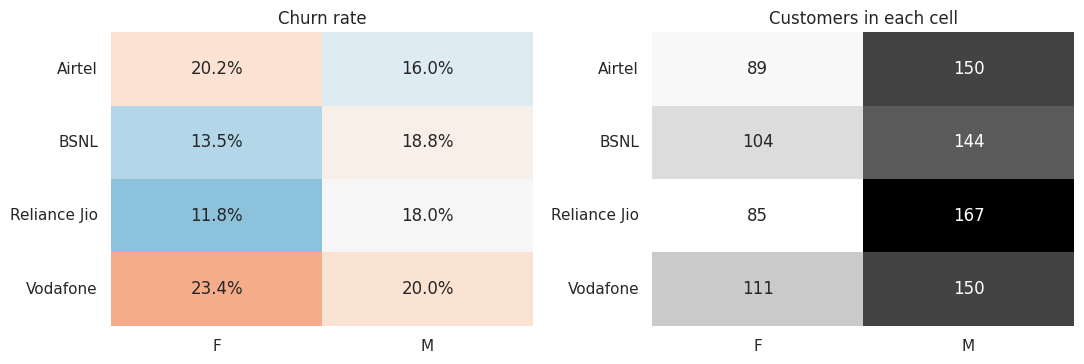

In [ ]:
# (V1 addition) Visual: partner x gender churn rate next to the number of customers behind each cell
pg_rate = df.pivot_table(index="telecom_partner", columns="gender", values="churn", aggfunc="mean", observed=True)
pg_n = df.pivot_table(index="telecom_partner", columns="gender", values="churn", aggfunc="count", observed=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(pg_rate, annot=True, fmt=".1%", cmap="RdBu_r", center=df["churn"].mean(),
            vmin=0.03, vmax=0.33, ax=axes[0], cbar=False)
axes[0].set_title("Churn rate")
sns.heatmap(pg_n, annot=True, fmt=".0f", cmap="Greys", ax=axes[1], cbar=False)
axes[1].set_title("Customers in each cell")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Note:
* The right panel shows how many customers sit behind each rate: 85 to 167 per cell, which means only about 10 to 30 churners per cell.
* Women churn more than men on Airtel (20.2% vs 16.0%) and Vodafone (23.4% vs 20.0%), while men churn more on BSNL (18.8% vs 13.5%) and Jio (18.0% vs 11.8%). The direction flips between partners, and the gaps are 3 to 6 points, which is within chance for cells this small. I do not treat this as a reliable interaction.

##**EDA Summary**

* Churn is 17.9%, imbalanced but workable. I use stratified splits and judge models on recall, precision and ROC-AUC.
* No single variable significantly predicts churn. Every test and correlation is null.
* The faint non-linear hints are in calls, SMS, salary and age, and these are where a model might find something.
* Realistic expectation: I expect a model on this data to reach only a ROC-AUC of around 0.5 to 0.6. I report that honestly rather than forcing a better result, and it is still a valid result ("churn is not explained by these attributes"). The spec's richer dataset would likely do better.

#**Block 4: Feature Engineering**

In [ ]:
df = df.drop(columns=["date_of_registration", "state"])
print(df.shape)   # (1000, 10)

(1000, 10)


Note:
* I drop `date_of_registration` because all customers registered within 6 days, with almost exactly 200 per day. It cannot distinguish customers, and it showed no link to churn.
* I drop `state` because it has 28 values with only about 36 customers each. A model would just memorise noise, and the earlier test showed no real link to churn (p = 0.69). It was also inconsistent with `city`.
* I keep `city` because it has just 6 well-populated groups, so it carries little overfitting risk. To drop it as well, add `"city"` to the list. Its p-value was 0.64, so the loss would be small.

In [ ]:
# Encode categorical columns
df = pd.get_dummies(df, columns=["telecom_partner", "gender", "city"],
                    drop_first=True, dtype=int)
print(df.shape)   # (1000, 16)
print(df.isna().sum().sum(), df.select_dtypes(exclude="number").columns.tolist())  # 0, []

(1000, 16)
0 []


Note:
* Models need numbers, so each category becomes 0/1 columns. `drop_first=True` removes one column per group (for example, Airtel, Bangalore and Female become the baselines), which avoids redundant columns. The result is 15 features plus `churn`, all numeric, with no nulls. The new columns are `telecom_partner_BSNL`, `telecom_partner_Reliance Jio`, `telecom_partner_Vodafone`, `gender_M`, `city_Chennai`, `city_Delhi`, `city_Hyderabad`, `city_Kolkata` and `city_Mumbai`. `num_dependents` stays numeric because it is an ordered count.

In [ ]:
# Separate features and target
X = df.drop(columns="churn")
y = df["churn"]
print(X.shape, y.shape)   # (1000, 15) (1000,)

(1000, 15) (1000,)


Note:
* `X` holds the 15 inputs and `y` holds the target to predict. Customer IDs remain as the index in both, so any prediction can be traced back to a customer.

In [ ]:
# Stratified train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))
print(y_train.sum(), y_test.sum())

(800, 15) (200, 15)
0.179 0.18
143 36


Note:
* 800 customers go to training and 200 to testing.
* `stratify=y` keeps the churn rate the same in both: 17.9% in training (143 churners) and 18.0% in testing (36 churners). Without it, a random split could leave the test set with very few churners.
* `random_state=42` makes the split reproducible, and no customer appears in both sets.
* A caution: the test set has only 36 churners, so test metrics will be noisy. A single recall or precision figure could swing by several percentage points depending on the split, which is why I also use cross-validation in the next step.

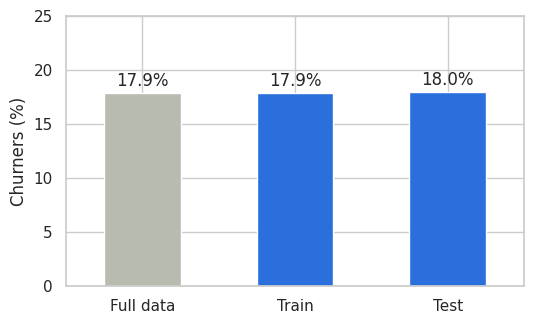

In [ ]:
# (V1 addition) Visual: stratification keeps the churn share equal in train and test
shares = pd.Series({"Full data": y.mean(), "Train": y_train.mean(), "Test": y_test.mean()}) * 100
ax = shares.plot(kind="bar", color=[V1_GREY, ACCENT, ACCENT], width=0.5, figsize=(5.5, 3.4))
ax.set_ylim(0, 25); ax.set_ylabel("Churners (%)"); ax.tick_params(axis="x", labelrotation=0)
for i, v in enumerate(shares):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

Note:
* The churn share is 17.9% in the full data and in training, and 18.0% in the test set, so stratification worked. The test set still has only 36 churners, which is why single-split metrics move around.

Note:
* Why scaling is not applied here: Scaling (for example, `StandardScaler`) is needed for logistic regression but not for tree models. If `df` were scaled now, the test data would influence the scaling and leak information. I therefore do the scaling inside a pipeline during modelling, so that it is fitted on the training data only.
* State of `df` now: 1,000 rows × 16 columns, all numeric, no nulls, with `X_train`, `X_test`, `y_train` and `y_test` ready.

#**Block 5: Model Creation and Validation**

In [ ]:
# Compare four models with cross-validation (training data only)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Dummy (always stay)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("m", LogisticRegression(class_weight="balanced", max_iter=1000))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            min_samples_leaf=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(5, shuffle=True, random_state=42)
scoring = {"auc": "roc_auc", "recall": "recall", "precision": "precision", "f1": "f1", "acc": "accuracy"}

rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{k: r[f"test_{k}"].mean().round(3) for k in scoring}})
print(pd.DataFrame(rows).set_index("model"))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

                       auc  recall  precision     f1    acc
model                                                      
Dummy (always stay)  0.500   0.000      0.000  0.000  0.821
Logistic Regression  0.421   0.344      0.133  0.191  0.492
Random Forest        0.530   0.021      0.150  0.037  0.809
Gradient Boosting    0.520   0.063      0.205  0.094  0.790


Note:
* The scaler sits inside the pipeline, so it is fitted only on each training fold. Class imbalance is handled with `class_weight="balanced"` for logistic regression and the random forest. Gradient boosting is fitted without class weights.
* ROC-AUC of 0.5 means no better than a coin flip. No real model clearly beats the dummy, and logistic regression falls below 0.5. The dummy's 82% accuracy shows why accuracy is misleading here: it catches zero churners.

In [ ]:
# Evaluate on the held-out test set
from sklearn.metrics import (roc_auc_score, recall_score, precision_score,
                             f1_score, accuracy_score, confusion_matrix)

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"model": name, "auc": round(roc_auc_score(y_test, prob), 3),
                 "recall": round(recall_score(y_test, pred), 3),
                 "precision": round(precision_score(y_test, pred, zero_division=0), 3),
                 "f1": round(f1_score(y_test, pred), 3),
                 "acc": round(accuracy_score(y_test, pred), 3),
                 "TP": tp, "FP": fp, "FN": fn, "TN": tn})
print(pd.DataFrame(rows).set_index("model"))

                       auc  recall  precision     f1    acc  TP  FP  FN   TN
model                                                                       
Dummy (always stay)  0.500   0.000      0.000  0.000  0.820   0   0  36  164
Logistic Regression  0.536   0.639      0.219  0.326  0.525  23  82  13   82
Random Forest        0.513   0.028      0.500  0.053  0.820   1   1  35  163
Gradient Boosting    0.549   0.000      0.000  0.000  0.810   0   2  36  162


Note:

The test set has 200 customers, of whom 36 churned.

* Logistic Regression has the highest recall (0.64: it found 23 of 36 churners), but it flagged 105 customers to do so, so only 22% of its flags were right (precision 0.22). Its accuracy of 52% is barely better than guessing at random.
* Random Forest flagged only 2 customers and caught 1 of the 36 churners (recall 0.03, precision 0.50). The precision rests on a single correct flag and is not meaningful.
* Gradient Boosting has the best test AUC (0.55) but flagged only 2 customers, neither of whom churned (recall 0).
* Test AUCs of 0.51 to 0.55 look like a small positive signal, but the shuffled-label check below shows that they are within the range of chance.

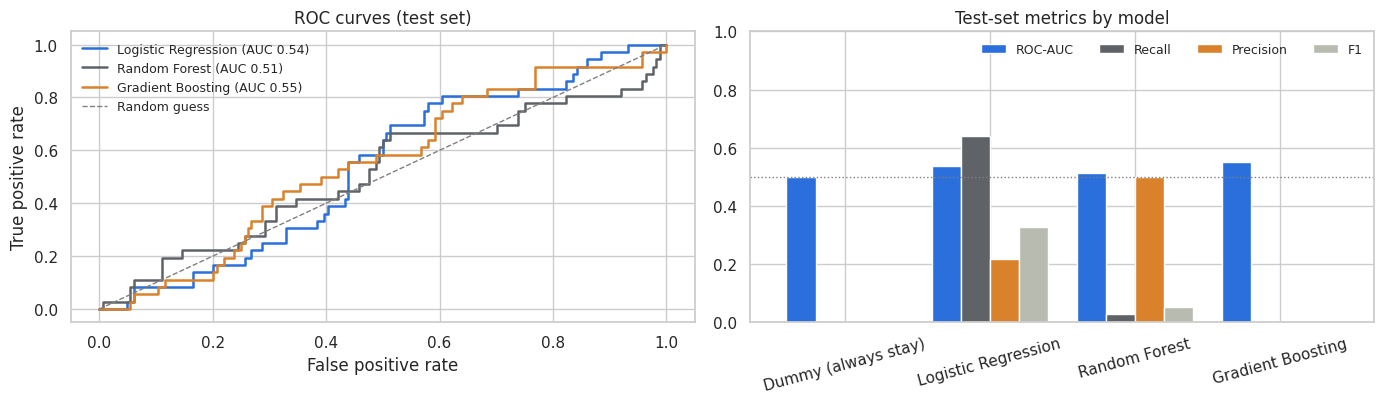

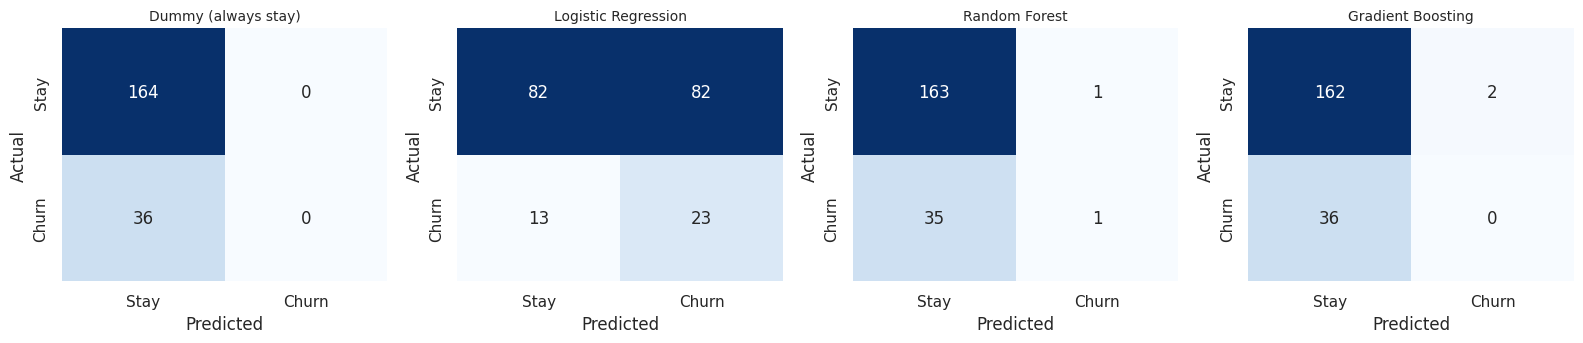

In [ ]:
# (V1 addition) Visual: ROC curves, metric comparison and confusion matrices on the test set
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# 1) ROC curves (the dummy model is a straight diagonal, so it is left out)
for (name, m), col in zip([(n, m) for n, m in models.items() if not n.startswith("Dummy")], V1_SERIES):
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, lw=1.8, color=col, label=f"{name} (AUC {roc_auc_score(y_test, prob):.2f})")
axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Random guess")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(frameon=False, fontsize=9)

# 2) Recall / precision / F1 / AUC side by side
metrics_v1 = {}
for name, m in models.items():
    pred = m.predict(X_test)
    metrics_v1[name] = {"ROC-AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
                        "Recall": recall_score(y_test, pred),
                        "Precision": precision_score(y_test, pred, zero_division=0),
                        "F1": f1_score(y_test, pred)}
mt = pd.DataFrame(metrics_v1).T
mt.plot(kind="bar", ax=axes[1], color=[ACCENT, "#5f6368", "#d9822b", V1_GREY], width=0.8)
axes[1].axhline(0.5, color="grey", ls=":", lw=1)
axes[1].set_title("Test-set metrics by model"); axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", labelrotation=15); axes[1].legend(frameon=False, fontsize=9, ncol=4)
plt.tight_layout(); plt.show()

# 3) Confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
    ax.set_title(name, fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

Note:
* The ROC curves hug the random-guess diagonal and cross it several times. Test AUCs of 0.54, 0.51 and 0.55 are only just above 0.5, and with 36 churners behind each curve the steps are coarse.
* The metric bars show the trade-off. Logistic regression finds the most churners (recall 0.64) but with low precision (0.22). The random forest flags only 2 customers, so its recall (0.03) and F1 (0.05) are near zero, while its precision bar (0.50) rests on a single correct flag. Gradient boosting catches no churners, so its recall, precision and F1 bars are empty (zero).
* The confusion matrices make this concrete: logistic regression flags 105 customers (82 + 23) to catch 23 of the 36 churners, the random forest flags 2 to catch 1, and gradient boosting flags 2 and catches none.

In [ ]:
# Sanity check — would random labels score the same?

rng = np.random.RandomState(0)
aucs = []
for i in range(20):
    y_shuffled = rng.permutation(y_train.values)          # destroy any real link to churn
    m = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                               min_samples_leaf=5, random_state=i).fit(X_train, y_shuffled)
    aucs.append(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]))
print(f"mean {np.mean(aucs):.3f}, sd {np.std(aucs):.3f}, max {np.max(aucs):.3f}")

mean 0.497, sd 0.051, max 0.581


Note:
* This is the most important check. The same random forest was trained 20 times on shuffled churn labels, where no real pattern can exist. The AUCs averaged 0.497 (sd 0.051, max 0.581). The real models' test AUCs (0.536, 0.513 and 0.549) all fall inside that range, so they cannot be distinguished from noise. With only 36 churners in the test set, small AUC differences mean very little. This agrees with the EDA, where every correlation and test was null.

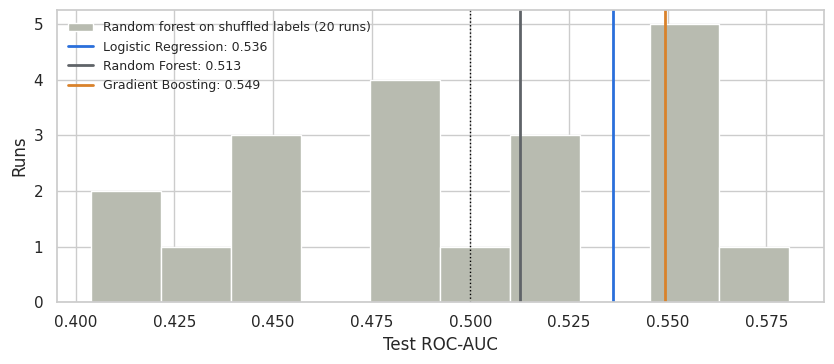

In [ ]:
# (V1 addition) Visual: the real test AUCs against the shuffled-label AUCs
real_auc = {n: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for n, m in models.items() if not n.startswith("Dummy")}

plt.figure(figsize=(8.5, 3.8))
plt.hist(aucs, bins=10, color=V1_GREY, edgecolor="white", label="Random forest on shuffled labels (20 runs)")
for (n, v), col in zip(real_auc.items(), V1_SERIES):
    plt.axvline(v, color=col, lw=2, label=f"{n}: {v:.3f}")
plt.axvline(0.5, color="black", ls=":", lw=1)
plt.xlabel("Test ROC-AUC"); plt.ylabel("Runs")
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.legend(frameon=False, fontsize=9, loc="upper left"); plt.tight_layout(); plt.show()

Note:
* The three real test AUCs (0.536, 0.513 and 0.549) sit inside the spread of the shuffled-label runs, which range from about 0.40 to 0.58. The best shuffled run (0.581) scores higher than all three real models. This is the picture version of the sanity check above: these AUCs cannot be told apart from noise.

In [ ]:
# Which features did the models use?

lr = models["Logistic Regression"]
coef = pd.Series(lr.named_steps["m"].coef_[0], index=X.columns)
print(coef.sort_values(key=abs, ascending=False).round(3).head(8))

rf = models["Random Forest"]
print(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).round(3).head(8))

city_Kolkata                    0.094
sms_sent                       -0.079
telecom_partner_Vodafone        0.078
num_dependents                  0.074
city_Hyderabad                 -0.071
telecom_partner_Reliance Jio   -0.065
city_Delhi                     -0.062
gender_M                        0.058
dtype: float64
estimated_salary        0.173
calls_made              0.166
data_used               0.154
sms_sent                0.141
age                     0.141
num_dependents          0.064
gender_M                0.026
telecom_partner_BSNL    0.023
dtype: float64


Note:
* The logistic regression coefficients are all tiny (the largest is 0.094 on standardised features), led by `city_Kolkata`, `sms_sent` and `telecom_partner_Vodafone`. Those match the faint patterns seen in the EDA but are far too small to rely on.
* The random forest spreads importance across the continuous columns (`estimated_salary` 0.17, `calls_made` 0.17, `data_used` 0.15, `sms_sent` 0.14, `age` 0.14). Importance this even is a typical sign of a model fitting noise, because on random data a forest uses whatever splits happen to fit the training set.

##**Handling the Class Imbalance with SMOTE**

Note:
* Only 17.9% of customers churn, so a model can score well by mostly predicting "stay". So far I have handled this with `class_weight="balanced"`. Here I try the second standard remedy: **SMOTE** (Synthetic Minority Over-sampling Technique). It creates new churner rows by interpolating between a real churner and one of its nearest churner neighbours, until both classes are the same size.
* I apply SMOTE **only to the training data, inside each cross-validation fold**. Validation folds and the test set are never oversampled, otherwise synthetic rows would leak into the evaluation and inflate the scores.
* The `imbalanced-learn` package could not be installed in the environment used to build this version, so I write SMOTE in a few lines of scikit-learn below. It follows the SMOTE-NC recipe for mixed columns: continuous columns are interpolated, the 0/1 columns (partner, gender, city) take the most common value among the neighbours, and `age` and `num_dependents` are rounded to whole numbers. The library version, `imblearn.over_sampling.SMOTENC`, can replace `smote_oversample` (I did not use or test it here).

In [ ]:
# (V1 addition) SMOTE written with scikit-learn only
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.neighbors import NearestNeighbors


def smote_oversample(X, y, categorical=(), integer=(), k=5, ratio=1.0, random_state=42):
    """Create synthetic minority (class 1) rows until minority = ratio x majority.
    categorical : column positions holding 0/1 flags (take the most common value among the k neighbours)
    integer     : column positions that must stay whole numbers (rounded after interpolation)"""
    rng = np.random.RandomState(random_state)
    Xa, ya = np.asarray(X, dtype=float), np.asarray(y)
    X_min = Xa[ya == 1]
    n_new = int(round(ratio * (ya == 0).sum())) - len(X_min)
    if n_new <= 0:
        return Xa, ya

    cont = [j for j in range(Xa.shape[1]) if j not in categorical]
    # distance space: continuous columns as z-scores, flags as 0/1 (a mismatch counts like a 1-SD difference)
    mu, sd = Xa[:, cont].mean(axis=0), Xa[:, cont].std(axis=0) + 1e-9
    Z = np.empty_like(X_min)
    Z[:, cont] = (X_min[:, cont] - mu) / sd
    if len(categorical):
        Z[:, list(categorical)] = X_min[:, list(categorical)]

    nn = NearestNeighbors(n_neighbors=min(k, len(X_min) - 1) + 1).fit(Z)
    neigh = nn.kneighbors(Z, return_distance=False)[:, 1:]            # drop the point itself
    base = rng.randint(0, len(X_min), n_new)                           # a real churner to start from
    pick = neigh[base, rng.randint(0, neigh.shape[1], n_new)]          # one of its nearest churner neighbours
    gap = rng.rand(n_new, 1)
    synth = X_min[base] + gap * (X_min[pick] - X_min[base])            # a point on the line between the two

    if len(categorical):
        cat = list(categorical)
        votes = X_min[neigh[base]][:, :, cat].mean(axis=1)             # share of neighbours whose flag is 1
        synth[:, cat] = np.where(votes > 0.5, 1.0, np.where(votes < 0.5, 0.0, X_min[base][:, cat]))
    if len(integer):
        synth[:, list(integer)] = np.round(synth[:, list(integer)])
    return np.vstack([Xa, synth]), np.concatenate([ya, np.ones(n_new, dtype=ya.dtype)])


class SMOTEClassifier(ClassifierMixin, BaseEstimator):
    """Oversamples the training data with SMOTE inside fit(), then fits the wrapped model.
    predict / predict_proba never resample, so validation folds and the test set stay untouched."""
    def __init__(self, estimator, categorical=(), integer=(), k=5, ratio=1.0, random_state=42):
        self.estimator = estimator
        self.categorical = categorical
        self.integer = integer
        self.k = k
        self.ratio = ratio
        self.random_state = random_state

    def fit(self, X, y):
        X_res, y_res = smote_oversample(X, y, self.categorical, self.integer, self.k, self.ratio, self.random_state)
        if hasattr(X, "columns"):
            X_res = pd.DataFrame(X_res, columns=X.columns)
        self.estimator_ = clone(self.estimator).fit(X_res, y_res)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


# Which columns are 0/1 flags and which must stay whole numbers
cat_pos = [i for i, c in enumerate(X.columns) if c.startswith(("telecom_partner_", "gender_", "city_"))]
int_pos = [X.columns.get_loc(c) for c in ["age", "num_dependents"]]
print("0/1 flag columns:", [X.columns[i] for i in cat_pos])
print("whole-number columns:", [X.columns[i] for i in int_pos])

0/1 flag columns: ['telecom_partner_BSNL', 'telecom_partner_Reliance Jio', 'telecom_partner_Vodafone', 'gender_M', 'city_Chennai', 'city_Delhi', 'city_Hyderabad', 'city_Kolkata', 'city_Mumbai']
whole-number columns: ['age', 'num_dependents']


Note:
* `smote_oversample` and `SMOTEClassifier` are defined once and reused in the cells below. The printout lists the nine 0/1 columns (partner, gender, city) that take the neighbours' most common value, and the two columns (`age`, `num_dependents`) that are kept as whole numbers.

Class counts before: {0: 657, 1: 143} | after: {0: 657, 1: 657}
Synthetic rows added: 514 | test set unchanged: (200, 15)
0/1 columns still only 0 or 1: True
age and num_dependents are whole numbers: True
Synthetic rows stay inside the real churners' range (every column): True


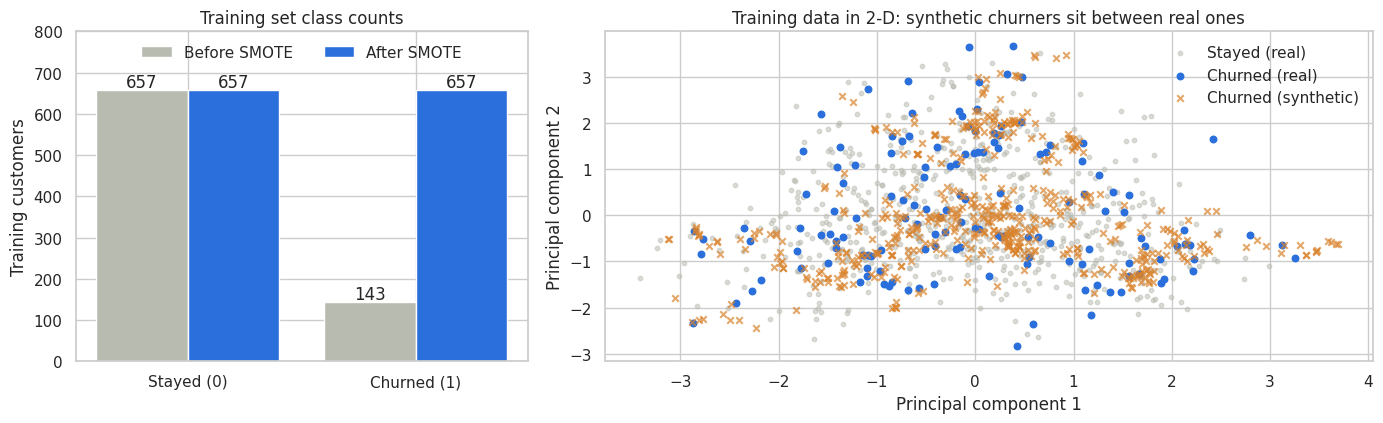

In [ ]:
# (V1 addition) What SMOTE does to the training set
X_s, y_s = smote_oversample(X_train, y_train, categorical=cat_pos, integer=int_pos, k=5, random_state=42)
n_real = len(X_train)
print("Class counts before:", y_train.value_counts().sort_index().to_dict(),
      "| after:", pd.Series(y_s).value_counts().sort_index().to_dict())
print("Synthetic rows added:", len(y_s) - n_real, "| test set unchanged:", X_test.shape)

# Sanity checks on the synthetic rows
synth_rows = X_s[n_real:]
print("0/1 columns still only 0 or 1:", bool(np.isin(synth_rows[:, cat_pos], [0, 1]).all()))
print("age and num_dependents are whole numbers:", bool(np.allclose(synth_rows[:, int_pos], np.round(synth_rows[:, int_pos]))))
real_min = np.asarray(X_train)[np.asarray(y_train) == 1]
print("Synthetic rows stay inside the real churners' range (every column):",
      bool(((synth_rows >= real_min.min(axis=0) - 1e-9) & (synth_rows <= real_min.max(axis=0) + 1e-9)).all()))

# Picture: class counts, and where the synthetic churners land (2-D PCA view)
from sklearn.decomposition import PCA
P = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(X_s))
is_syn = np.arange(len(y_s)) >= n_real

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.7]})
ct_b, ct_a = y_train.value_counts().sort_index(), pd.Series(y_s).value_counts().sort_index()
pos = np.arange(2)
axes[0].bar(pos - 0.2, ct_b.values, width=0.4, color=V1_GREY, label="Before SMOTE")
axes[0].bar(pos + 0.2, ct_a.values, width=0.4, color=ACCENT, label="After SMOTE")
for p, v in zip(pos - 0.2, ct_b.values): axes[0].text(p, v + 8, str(v), ha="center")
for p, v in zip(pos + 0.2, ct_a.values): axes[0].text(p, v + 8, str(v), ha="center")
axes[0].set_xticks(pos); axes[0].set_xticklabels(["Stayed (0)", "Churned (1)"])
axes[0].set_ylabel("Training customers"); axes[0].set_title("Training set class counts")
axes[0].set_ylim(0, 800); axes[0].legend(frameon=False, loc="upper center", ncol=2)

axes[1].scatter(P[(y_s == 0) & ~is_syn, 0], P[(y_s == 0) & ~is_syn, 1], s=10, color=V1_GREY, alpha=0.5, label="Stayed (real)")
axes[1].scatter(P[(y_s == 1) & ~is_syn, 0], P[(y_s == 1) & ~is_syn, 1], s=22, color=ACCENT, label="Churned (real)")
axes[1].scatter(P[is_syn, 0], P[is_syn, 1], s=22, color="#d9822b", alpha=0.7, marker="x", label="Churned (synthetic)")
axes[1].set_xlabel("Principal component 1"); axes[1].set_ylabel("Principal component 2")
axes[1].set_title("Training data in 2-D: synthetic churners sit between real ones"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

Note:
* SMOTE added 514 synthetic churners to the 800-customer training set, taking churners from 143 to 657, equal to the 657 stayers. The checks all print `True`: the 0/1 columns stay 0 or 1, `age` and `num_dependents` stay whole numbers, and every synthetic value lies inside the range of the real churners, as expected for points interpolated between real ones. The test set is unchanged (200 rows).
* In the 2-D view, the synthetic churners (orange crosses) fill the same cloud as the real churners and stayers. SMOTE can only recombine what the real churners already look like, and because they overlap heavily with the stayers, it adds no new information.

In [ ]:
# (V1 addition) Class-weight baseline vs SMOTE: cross-validation on the training data, then the held-out test set
cv_v1 = StratifiedKFold(5, shuffle=True, random_state=42)
from sklearn.metrics import make_scorer
scoring_v1 = {"auc": "roc_auc", "recall": "recall",
              "precision": make_scorer(precision_score, zero_division=0),      # 0 instead of a warning when a fold flags nobody
              "f1": make_scorer(f1_score, zero_division=0)}


def make_models(strategy):
    weight = "balanced" if strategy == "class_weight" else None
    base = {
        "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                         ("m", LogisticRegression(class_weight=weight, max_iter=1000))]),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight=weight,
                                                min_samples_leaf=5, random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }
    if strategy == "SMOTE":
        return {n: SMOTEClassifier(m, categorical=cat_pos, integer=int_pos, k=5, random_state=42)
                for n, m in base.items()}
    return base


cv_rows, test_rows, fitted_v1 = [], [], {}
for strategy in ["class_weight", "SMOTE"]:
    for name, m in make_models(strategy).items():
        r = cross_validate(m, X_train, y_train, cv=cv_v1, scoring=scoring_v1)
        cv_rows.append({"strategy": strategy, "model": name,
                        **{k: r[f"test_{k}"].mean() for k in scoring_v1}, "auc_sd": r["test_auc"].std()})
        m.fit(X_train, y_train)
        fitted_v1[(strategy, name)] = m
        pred, prob = m.predict(X_test), m.predict_proba(X_test)[:, 1]
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        test_rows.append({"strategy": strategy, "model": name, "auc": roc_auc_score(y_test, prob),
                          "recall": recall_score(y_test, pred),
                          "precision": precision_score(y_test, pred, zero_division=0),
                          "f1": f1_score(y_test, pred), "TP": tp, "FP": fp, "FN": fn, "TN": tn})

res_cv = pd.DataFrame(cv_rows).set_index(["model", "strategy"]).sort_index().round(3)
res_test = pd.DataFrame(test_rows).set_index(["model", "strategy"]).sort_index().round(3)
print("Cross-validation on the training data (5 folds)\n", res_cv, "\n")
print("Held-out test set\n", res_test)

Cross-validation on the training data (5 folds)
                                     auc  recall  precision     f1  auc_sd
model               strategy                                             
Gradient Boosting   SMOTE         0.486   0.174      0.161  0.167   0.051
                    class_weight  0.520   0.063      0.205  0.094   0.049
Logistic Regression SMOTE         0.465   0.161      0.153  0.155   0.032
                    class_weight  0.421   0.344      0.133  0.191   0.038
Random Forest       SMOTE         0.465   0.098      0.159  0.120   0.077
                    class_weight  0.530   0.021      0.150  0.037   0.046 

Held-out test set
                                     auc  recall  precision     f1  TP  FP  FN  \
model               strategy                                                    
Gradient Boosting   SMOTE         0.536   0.306      0.204  0.244  11  43  25   
                    class_weight  0.549   0.000      0.000  0.000   0   2  36   
Logistic Regre

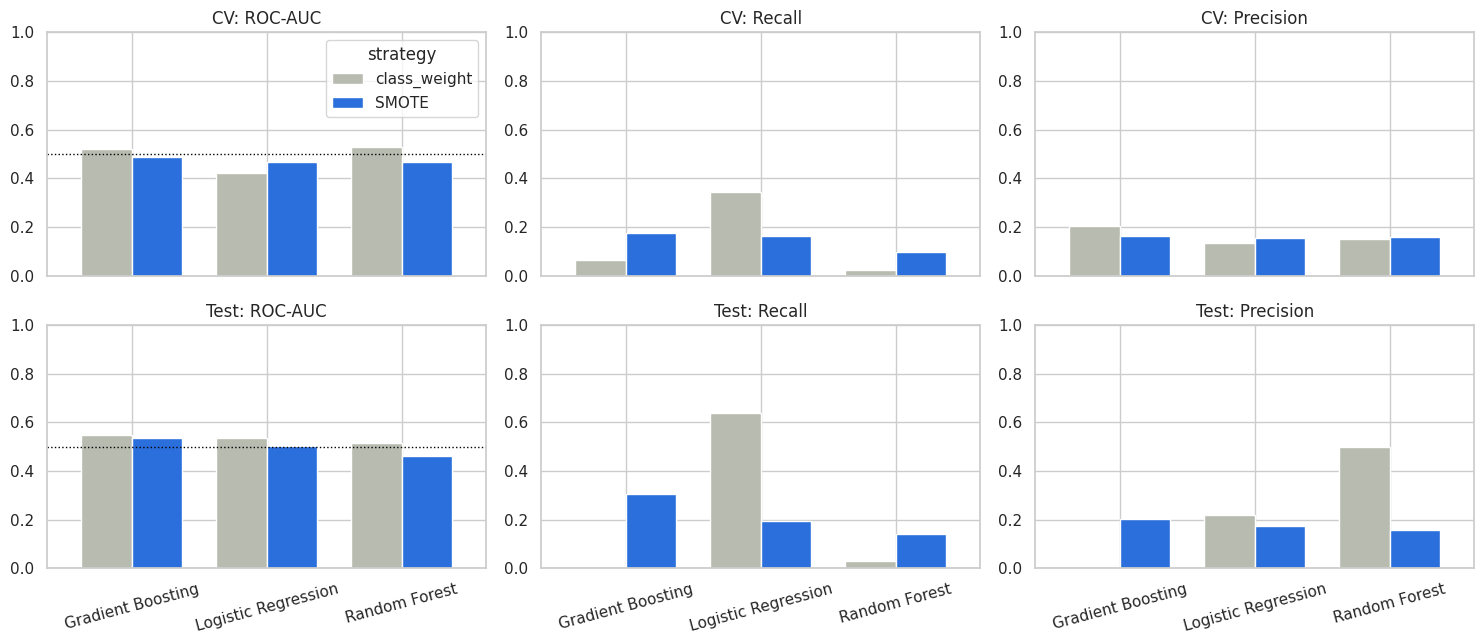

In [ ]:
# (V1 addition) Visual: class-weight vs SMOTE, per model
fig, axes = plt.subplots(2, 3, figsize=(15, 6.6), sharex=True)
for row, (title, tbl) in enumerate([("CV", res_cv), ("Test", res_test)]):
    for col, metric in enumerate(["auc", "recall", "precision"]):
        ax = axes[row, col]
        pv = tbl[metric].unstack("strategy")[["class_weight", "SMOTE"]]
        pv.plot(kind="bar", ax=ax, color=[V1_GREY, ACCENT], width=0.75, legend=(row == 0 and col == 0))
        if metric == "auc":
            ax.axhline(0.5, color="black", ls=":", lw=1)
        ax.set_title(f"{title}: {'ROC-AUC' if metric == 'auc' else metric.capitalize()}")
        ax.set_xlabel(""); ax.tick_params(axis="x", labelrotation=15); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

Note:
* **SMOTE does not improve these models.** Test ROC-AUC falls for all three (random forest 0.513 to 0.462, gradient boosting 0.549 to 0.536, logistic regression 0.536 to 0.501). In cross-validation it falls for gradient boosting (0.520 to 0.486) and the random forest (0.530 to 0.465) and rises for logistic regression (0.421 to 0.465). Every ROC-AUC value in both strategies sits between 0.42 and 0.55, around chance.
* What changes is how many customers each model flags, not how well it flags them. On the test set, gradient boosting goes from 2 flagged customers (recall 0) to 54 (11 caught, recall 0.31), the random forest goes from 2 flagged (1 caught, recall 0.03) to 32 (5 caught, recall 0.14), and logistic regression goes from 105 flagged (recall 0.64) to 40 (recall 0.19). Apart from the two baseline tree models on the test set (which flag only 2 customers each), precision stays between 0.13 and 0.22, close to the 17.9% base rate, which is what a model with no signal looks like.
* The class-weight rows reproduce the earlier results exactly (for example, logistic regression test AUC 0.536, recall 0.639), so the two strategies are compared on the same split and folds.

Shuffled labels + SMOTE: mean 0.506, sd 0.049, max 0.613
Real labels + SMOTE random forest, test AUC: 0.462


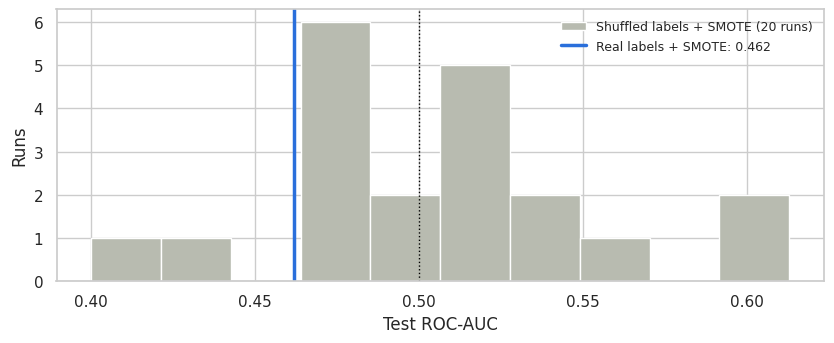

In [ ]:
# (V1 addition) Does SMOTE create signal where there is none? Same shuffled-label test as before, now with SMOTE
rng_s = np.random.RandomState(0)
aucs_smote = []
for i in range(20):
    y_shuf_s = rng_s.permutation(y_train.values)                      # destroy any real link to churn
    m_s = SMOTEClassifier(RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=i),
                          categorical=cat_pos, integer=int_pos, k=5, random_state=i).fit(X_train, y_shuf_s)
    aucs_smote.append(roc_auc_score(y_test, m_s.predict_proba(X_test)[:, 1]))
print(f"Shuffled labels + SMOTE: mean {np.mean(aucs_smote):.3f}, sd {np.std(aucs_smote):.3f}, max {np.max(aucs_smote):.3f}")
real_smote_rf = res_test.loc[("Random Forest", "SMOTE"), "auc"]
print("Real labels + SMOTE random forest, test AUC:", real_smote_rf)

plt.figure(figsize=(8.5, 3.6))
plt.hist(aucs_smote, bins=10, color=V1_GREY, edgecolor="white", label="Shuffled labels + SMOTE (20 runs)")
plt.axvline(real_smote_rf, color=ACCENT, lw=2.5, label=f"Real labels + SMOTE: {real_smote_rf:.3f}")
plt.axvline(0.5, color="black", ls=":", lw=1)
plt.xlabel("Test ROC-AUC"); plt.ylabel("Runs"); plt.legend(frameon=False, fontsize=9)
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

Note:
* With shuffled labels, SMOTE plus a random forest scores a mean test AUC of 0.506 (max 0.613). The real-label version scores 0.462, which is below that average and inside the spread. SMOTE did not find a pattern that class weighting had missed, which matches the plot above.

##**Feature Importance for the Tree-Based Models**

Note:
* Two kinds of importance are shown for the Random Forest and Gradient Boosting models, each trained with the baseline setting (class weights for the random forest, no weighting for gradient boosting) and with SMOTE.
* **Impurity-based importance** is how much a column reduced the trees' impurity during training. It is fast, but it favours columns with many distinct values and is measured on the training data.
* **Permutation importance** shuffles one column of the *held-out test set* and measures how much ROC-AUC drops. It is slower but a fairer test of whether a column helps on unseen customers. Blue bars mean that the drop is clearly above zero (the mean minus two standard deviations is positive).
* A final check adds a column of pure random numbers. Any real feature that cannot rank above that noise column carries no usable signal.

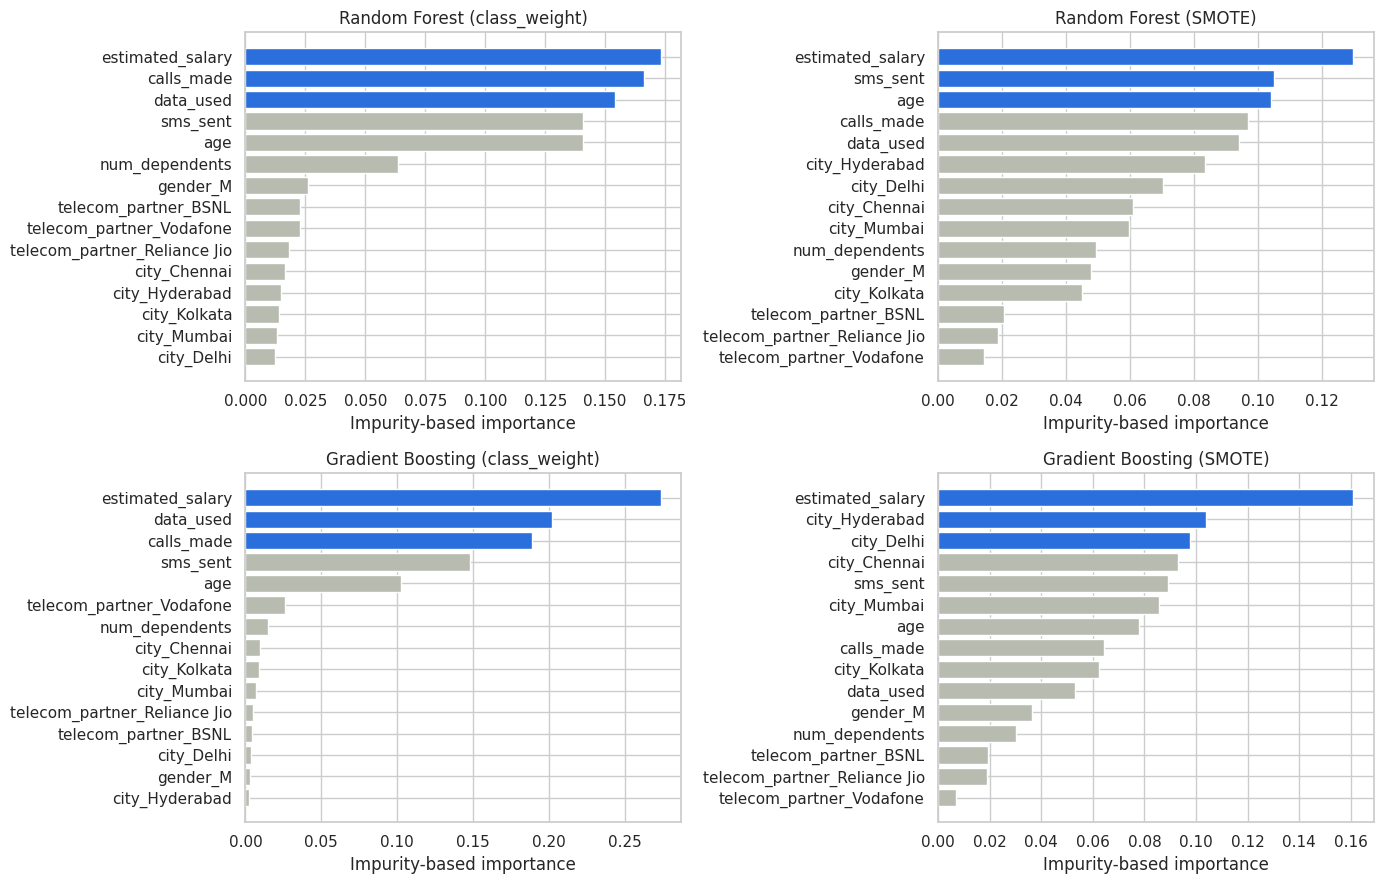

                              Random Forest (class_weight)  \
estimated_salary                                     0.173   
calls_made                                           0.166   
data_used                                            0.154   
sms_sent                                             0.141   
age                                                  0.141   
num_dependents                                       0.064   
gender_M                                             0.026   
telecom_partner_BSNL                                 0.023   
telecom_partner_Vodafone                             0.023   
telecom_partner_Reliance Jio                         0.018   
city_Chennai                                         0.017   
city_Hyderabad                                       0.015   
city_Kolkata                                         0.014   
city_Delhi                                           0.013   
city_Mumbai                                          0.013   

       

In [ ]:
# (V1 addition) Impurity-based feature importance: Random Forest and Gradient Boosting, with and without SMOTE
def tree_of(fitted):                          # SMOTE models keep the real tree model in .estimator_
    return fitted.estimator_ if isinstance(fitted, SMOTEClassifier) else fitted

imp_panels = [("Random Forest", "class_weight"), ("Random Forest", "SMOTE"),
              ("Gradient Boosting", "class_weight"), ("Gradient Boosting", "SMOTE")]
imp_tbl = pd.DataFrame({f"{n} ({s})": pd.Series(tree_of(fitted_v1[(s, n)]).feature_importances_, index=X.columns)
                        for n, s in imp_panels})

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), imp_tbl.columns):
    s = imp_tbl[col].sort_values()
    colors = [ACCENT if i >= len(s) - 3 else V1_GREY for i in range(len(s))]        # top 3 highlighted
    ax.barh(s.index, s.values, color=colors)
    ax.set_title(col); ax.set_xlabel("Impurity-based importance")
plt.tight_layout(); plt.show()

print(imp_tbl.round(3).sort_values(imp_tbl.columns[0], ascending=False))

Note:
* In the baseline models, the same continuous columns lead: `estimated_salary` (random forest 0.173, gradient boosting 0.274), `calls_made` (0.166, 0.189) and `data_used` (0.154, 0.202), followed by `sms_sent` and `age`. Partner, gender and city columns all score below 0.04.
* With SMOTE the order changes. City columns jump up (gradient boosting: Hyderabad 0.104, Delhi 0.098, Chennai 0.093), while `calls_made` and `data_used` drop (0.189 to 0.064 and 0.202 to 0.053 in gradient boosting). A ranking that reshuffles when only the resampling changes is not stable, which suggests that the trees are fitting noise.
* Impurity importance also favours continuous columns, because they offer many more split points than a 0/1 column. The noise check below tests this directly.

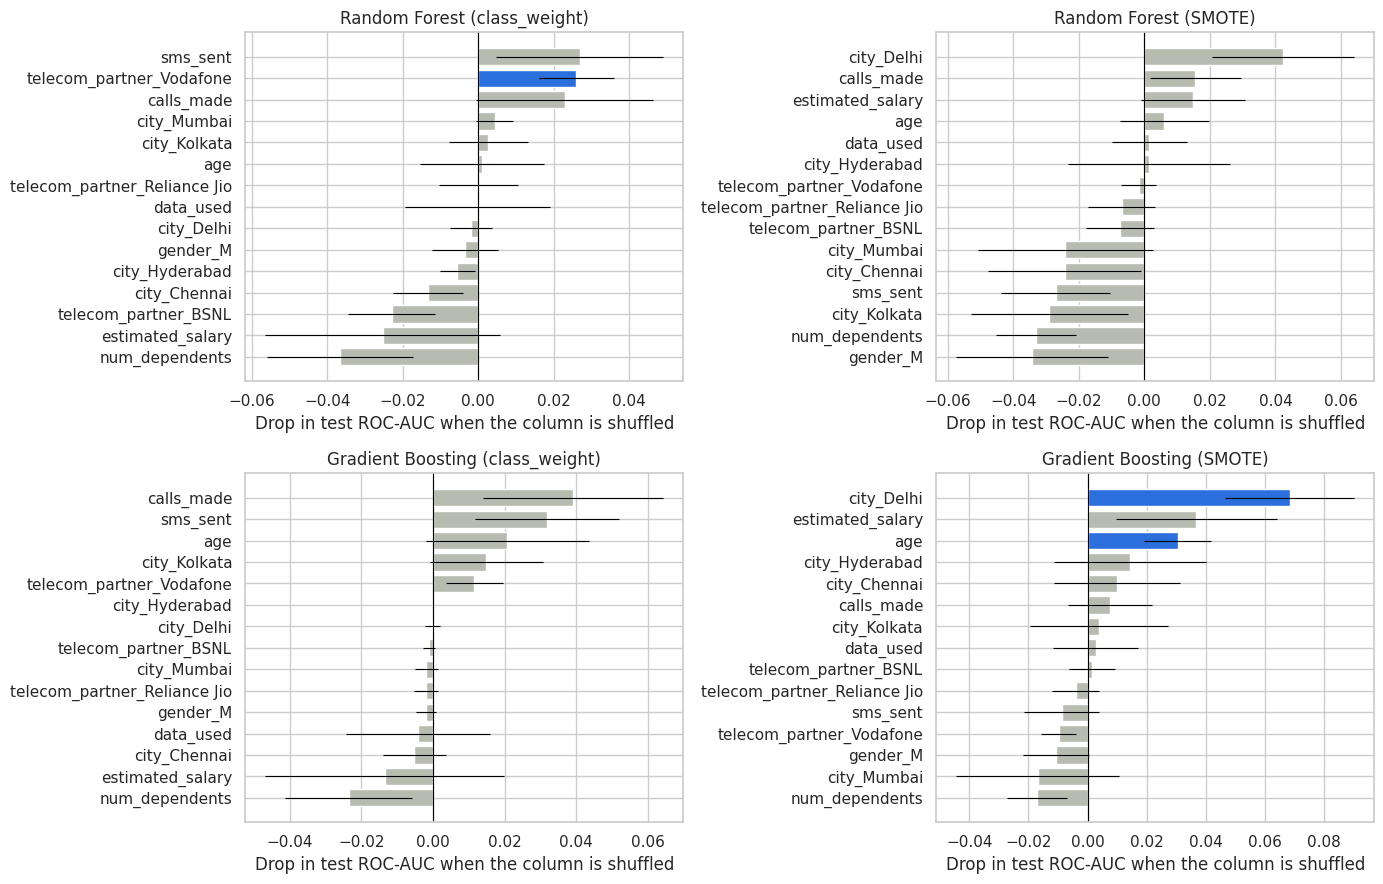

Random Forest (class_weight): 1 of 15 columns clearly above zero | largest = sms_sent (0.027)
Random Forest (SMOTE): 0 of 15 columns clearly above zero | largest = city_Delhi (0.042)
Gradient Boosting (class_weight): 0 of 15 columns clearly above zero | largest = calls_made (0.039)
Gradient Boosting (SMOTE): 2 of 15 columns clearly above zero | largest = city_Delhi (0.068)


In [ ]:
# (V1 addition) Permutation feature importance on the held-out test set
from sklearn.inspection import permutation_importance

perm_res = {}
for n, s in imp_panels:
    pi = permutation_importance(fitted_v1[(s, n)], X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=42)
    perm_res[f"{n} ({s})"] = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X.columns)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (label, tbl) in zip(axes.ravel(), perm_res.items()):
    t = tbl.sort_values("mean")
    clear = (t["mean"] - 2 * t["std"]) > 0                                           # clearly above zero
    ax.barh(t.index, t["mean"], xerr=t["std"], color=[ACCENT if c else V1_GREY for c in clear],
            error_kw={"ecolor": "black", "lw": 0.8})
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(label); ax.set_xlabel("Drop in test ROC-AUC when the column is shuffled")
plt.tight_layout(); plt.show()

for label, tbl in perm_res.items():
    clear_n = int(((tbl["mean"] - 2 * tbl["std"]) > 0).sum())
    print(f"{label}: {clear_n} of {len(tbl)} columns clearly above zero | largest = {tbl['mean'].idxmax()} ({tbl['mean'].max():.3f})")

Note:
* Permutation importance on the 200 test customers is much less flattering. In all four models most columns have an importance near zero or negative, meaning that shuffling them does not hurt the test AUC, and sometimes helps.
* Only 3 of the 60 column-model tests (4 models × 15 columns) clear the two-standard-deviation bar, and they differ between models: `telecom_partner_Vodafone` (random forest, class weights), and `city_Delhi` and `age` (gradient boosting, SMOTE). None clears it for the gradient boosting baseline or for the random forest with SMOTE. A handful of "clear" bars among 60 tests is not surprising by chance.
* The largest drops are `sms_sent` (0.027) in the random forest baseline and `calls_made` (0.039) in the gradient boosting baseline, but neither clears the bar. A drop of 0.03 to 0.04 in AUC on 36 churners is small.
* The error bars only capture shuffle-to-shuffle variation, not the fact that the test set has just 36 churners, so even the few clear bars are weak evidence.

Random Forest: 0 of 15 real features rank above the random-noise column
Gradient Boosting: 2 of 15 real features rank above the random-noise column


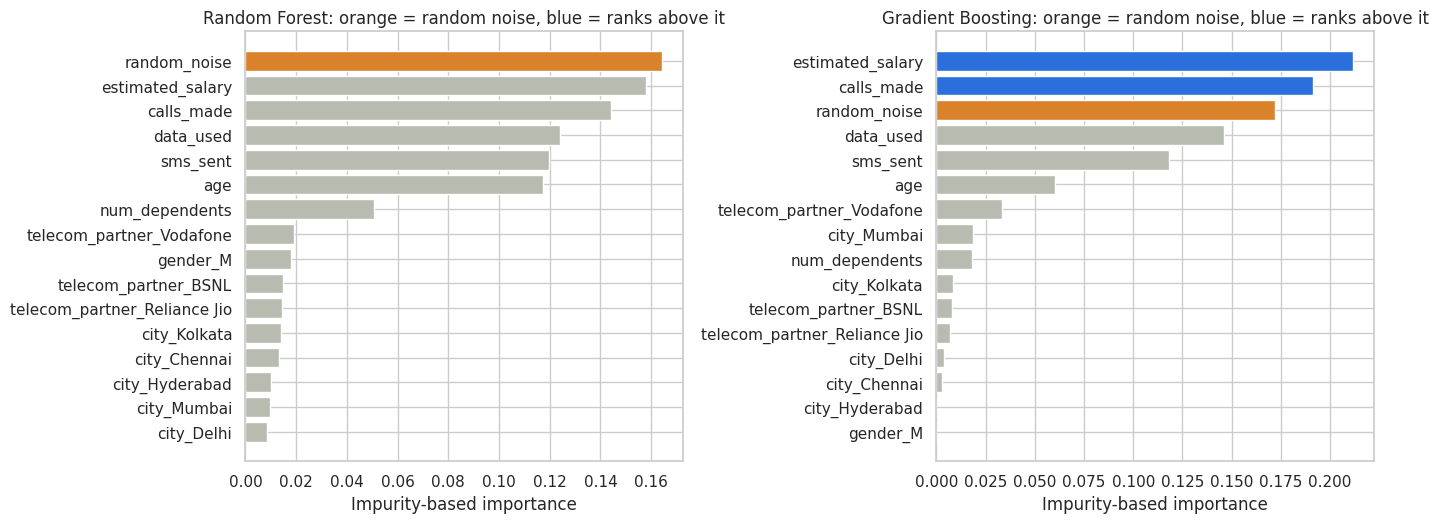

In [ ]:
# (V1 addition) Reality check: add a column of pure random numbers; real features ranking below it carry no signal
rng_n = np.random.RandomState(7)
Xn_train = X_train.assign(random_noise=rng_n.normal(size=len(X_train)))

probe = {
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            min_samples_leaf=5, random_state=42).fit(Xn_train, y_train),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42).fit(Xn_train, y_train),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, (name, m) in zip(axes, probe.items()):
    s = pd.Series(m.feature_importances_, index=Xn_train.columns).sort_values()
    cols = ["#d9822b" if i == "random_noise" else (ACCENT if v > s["random_noise"] else V1_GREY) for i, v in s.items()]
    ax.barh(s.index, s.values, color=cols)
    ax.set_title(f"{name}: orange = random noise, blue = ranks above it"); ax.set_xlabel("Impurity-based importance")
    above = int((s.drop("random_noise") > s["random_noise"]).sum())
    print(f"{name}: {above} of {len(s) - 1} real features rank above the random-noise column")
plt.tight_layout(); plt.show()

Note:
* A column of pure random numbers ranks **first** in the random forest (importance about 0.16, above all 15 real features) and third in gradient boosting, behind only `estimated_salary` and `calls_made`. By this test, 0 of 15 features in the random forest and 2 of 15 in gradient boosting rise above noise.
* This also explains the impurity chart: `estimated_salary`, `calls_made` and `data_used` sit on top because continuous columns get high impurity scores, not because they drive churn.

**Feature importance summary**
* No column is reliably important. Impurity rankings reshuffle under SMOTE, permutation importance finds almost nothing on the test set, and a random-noise column beats most real features. This is consistent with the EDA, where no variable had a significant link to churn.
* If a richer dataset arrives (customer service calls, plan type, per-period minutes), I can re-run these same cells to see which of those columns carry real signal.

In [ ]:
# Score every customer, out-of-fold
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

feature_cols = list(X.columns)          # the 15 features, fixed BEFORE adding score columns

model = Pipeline([("sc", StandardScaler()),
                  ("m", LogisticRegression(class_weight="balanced", max_iter=1000))])

cv = StratifiedKFold(5, shuffle=True, random_state=42)
score = cross_val_predict(model, df[feature_cols], df["churn"], cv=cv, method="predict_proba")[:, 1]

df["churn_risk_score"] = score.round(4)
print("AUC:", round(roc_auc_score(df["churn"], df["churn_risk_score"]), 3))

AUC: 0.467


Note:
* This adds a `churn_risk_score` column to `df` (a probability from 0 to 1). "Out-of-fold" means that each customer is scored by a model trained on the other 80% of customers, never by one that saw their own outcome. Scoring everyone with a model trained on everyone would flatter the results.
* The AUC is 0.467, and it stays at 0.45 to 0.48 across 10 different CV seeds. An AUC of 0.5 is random ranking, so these scores rank churners marginally worse than chance. Scores span only 0.30 to 0.71, with a mean of 0.495.

In [ ]:
# Is that AUC distinguishable from noise?
rng = np.random.RandomState(1)
null = []
for i in range(100):
    y_shuf = pd.Series(rng.permutation(df["churn"].values), index=df.index)
    s = cross_val_predict(model, df[feature_cols], y_shuf,
                          cv=StratifiedKFold(5, shuffle=True, random_state=i), method="predict_proba")[:, 1]
    null.append(roc_auc_score(y_shuf, s))
null = np.array(null)
print(null.mean().round(3), np.percentile(null, 95).round(3))
print("p-value:", (null >= roc_auc_score(df["churn"], df["churn_risk_score"])).mean())

0.496 0.547
p-value: 0.77


Note:
* With labels shuffled (no real signal possible), the same pipeline averages an AUC of 0.496, with a 95th percentile of 0.547. The real AUC (0.467) sits inside that noise (p = 0.77), so the model has found nothing. The slightly-below-0.5 value is a known quirk of cross-validating on pure noise, not a real inverse relationship.

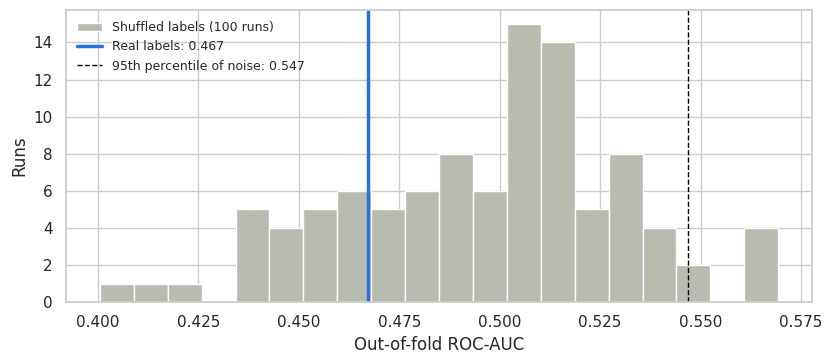

In [ ]:
# (V1 addition) Visual: the real out-of-fold AUC against 100 shuffled-label runs
real_oof_auc = roc_auc_score(df["churn"], df["churn_risk_score"])
p95 = np.percentile(null, 95)

plt.figure(figsize=(8.5, 3.8))
plt.hist(null, bins=20, color=V1_GREY, edgecolor="white", label="Shuffled labels (100 runs)")
plt.axvline(real_oof_auc, color=ACCENT, lw=2.5, label=f"Real labels: {real_oof_auc:.3f}")
plt.axvline(p95, color="black", ls="--", lw=1, label=f"95th percentile of noise: {p95:.3f}")
plt.xlabel("Out-of-fold ROC-AUC"); plt.ylabel("Runs")
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

Note:
* The real out-of-fold AUC (0.467, blue line) sits in the lower half of the shuffled-label distribution (which centres near 0.50 and spans about 0.40 to 0.57) and well to the left of the 95th percentile of noise (0.547). The churn risk scores are what would be expected from a model fitted to random labels.

In [ ]:
# Does a higher score mean more churn? (decile check)
df["risk_decile"] = pd.qcut(df["churn_risk_score"].rank(method="first"), 10, labels=range(1, 11)).astype(int)

dec = df.groupby("risk_decile").agg(customers=("churn", "size"), churners=("churn", "sum"),
                                    churn_rate=("churn", "mean")).round(3)
dec["lift"] = (dec["churn_rate"] / df["churn"].mean()).round(2)
print(dec.sort_index(ascending=False))

             customers  churners  churn_rate  lift
risk_decile                                       
10                 100         9        0.09  0.50
9                  100        17        0.17  0.95
8                  100        21        0.21  1.17
7                  100        17        0.17  0.95
6                  100        24        0.24  1.34
5                  100        17        0.17  0.95
4                  100        19        0.19  1.06
3                  100        15        0.15  0.84
2                  100        17        0.17  0.95
1                  100        23        0.23  1.28


Note:
* The "highest-risk" 100 customers actually churn at half the average rate (9% vs 17.9%). The lowest-risk decile churns more than average. There is no monotonic pattern, which confirms that the scores carry no usable information.

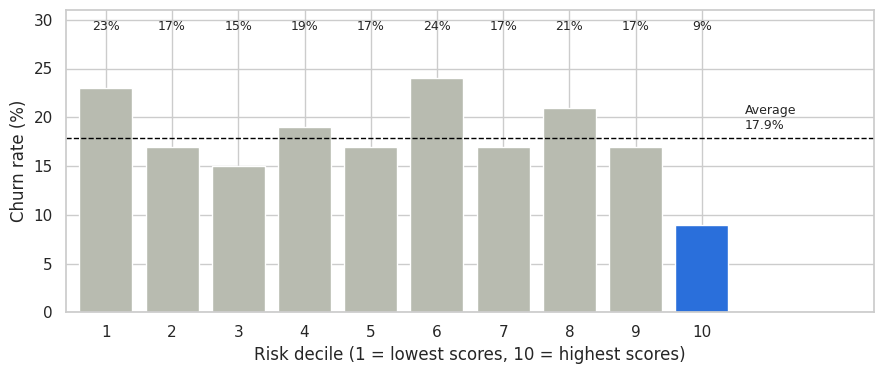

In [ ]:
# (V1 addition) Visual: churn rate by risk decile
dec_plot = dec.sort_index()                                           # decile 1 (lowest scores) to 10 (highest)
avg_rate = df["churn"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.bar(dec_plot.index.astype(str), dec_plot["churn_rate"] * 100,
       color=[ACCENT if i == 10 else V1_GREY for i in dec_plot.index])
ax.axhline(avg_rate, color="black", ls="--", lw=1)
ax.set_xlim(-0.6, 11.6)
ax.text(9.65, avg_rate + 0.6, f"Average\n{avg_rate:.1f}%", fontsize=9, va="bottom")           # direct label instead of a legend
for i, v in enumerate(dec_plot["churn_rate"] * 100):
    ax.text(i, 29, f"{v:.0f}%", ha="center", fontsize=9)                   # labels in one row, clear of the average line
ax.set_ylim(0, 31)
ax.set_xlabel("Risk decile (1 = lowest scores, 10 = highest scores)"); ax.set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()

Note:
* This is the same decile table as above, shown as bars. A useful score would climb from left to right. Instead, the bars wander between 15% and 24% for deciles 1 to 9, and the highest-scored decile (blue) is the lowest bar at 9% (9 of 100), half the 17.9% average.
* With 100 customers per decile, each bar carries about ±7 points of sampling noise, so only decile 10 stands out, and its 95% interval (roughly 5% to 16%) only just misses the average. It points the wrong way, but chance is a likelier explanation than a real reverse effect.

In [ ]:
# Create the churn flag
FLAG_TOP_PCT = 0.20                                    # flag the top 20% of scores
threshold = df["churn_risk_score"].quantile(1 - FLAG_TOP_PCT)

df["churn_flag"] = (df["churn_risk_score"] >= threshold).astype(int)
df["risk_band"] = pd.cut(df["churn_risk_score"],
                         bins=[0, df["churn_risk_score"].quantile(0.5), threshold, 1],
                         labels=["Low", "Medium", "High"], include_lowest=True)

print(df["churn_flag"].value_counts())
print(pd.crosstab(df["churn_flag"], df["churn"]))

churn_flag
0    800
1    200
Name: count, dtype: int64
churn         0    1
churn_flag          
0           647  153
1           174   26


Note:
* `churn_flag` is 1 for the top 20% of risk scores, which is the YES/NO flag the spec asks for. I chose a share-of-customers threshold rather than a fixed probability because the scores bunch near 0.5. `risk_band` splits customers into Low (bottom 50%), Medium and High (top 20%). `FLAG_TOP_PCT` can be changed to flag more or fewer customers.
* 200 customers are flagged, and only 26 of them actually churned (13.0% precision), against 17.9% for customers picked at random. The flag catches 26 of 179 churners (recall 14.5%), so choosing customers by coin toss would do better. A separate bootstrap check (not part of this notebook) gives an interval of 8.5% to 18.0% for the flagged group's churn rate, so even its best case only matches the base rate. Across other cut-offs, flagging the top 50% gives a lift of 0.98 and the top 30% gives 0.88. No threshold produces a lift above 1.

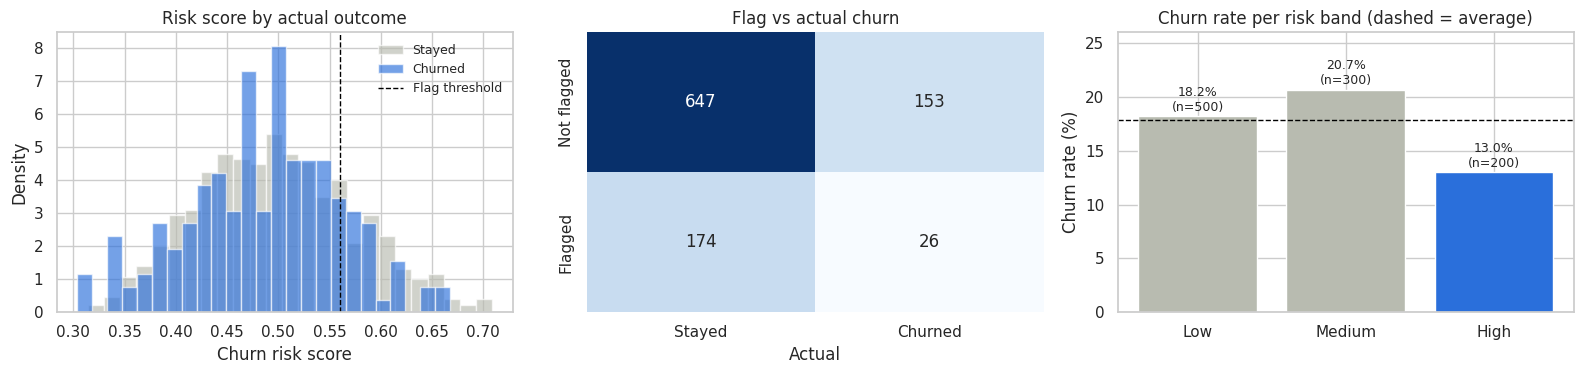

In [ ]:
# (V1 addition) Visual: score by actual outcome, flag vs actual churn, and churn rate per risk band
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))

for val, lab, col in [(0, "Stayed", V1_GREY), (1, "Churned", ACCENT)]:
    axes[0].hist(df.loc[df["churn"] == val, "churn_risk_score"], bins=25, density=True, alpha=0.65, color=col, label=lab)
axes[0].axvline(threshold, color="black", ls="--", lw=1, label="Flag threshold")
axes[0].set_xlabel("Churn risk score"); axes[0].set_ylabel("Density")
axes[0].set_title("Risk score by actual outcome"); axes[0].legend(frameon=False, fontsize=9)

ct_flag = pd.crosstab(df["churn_flag"], df["churn"])
sns.heatmap(ct_flag, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Stayed", "Churned"], yticklabels=["Not flagged", "Flagged"])
axes[1].set_xlabel("Actual"); axes[1].set_ylabel(""); axes[1].set_title("Flag vs actual churn")

band = df.groupby("risk_band", observed=True)["churn"].agg(["mean", "count"])
axes[2].bar(band.index.astype(str), band["mean"] * 100, color=[V1_GREY, V1_GREY, ACCENT])
axes[2].axhline(df["churn"].mean() * 100, color="black", ls="--", lw=1)
for i, (m_, n_) in enumerate(zip(band["mean"] * 100, band["count"])):
    axes[2].text(i, m_ + 0.5, f"{m_:.1f}%\n(n={n_})", ha="center", fontsize=9)
axes[2].set_ylabel("Churn rate (%)"); axes[2].set_ylim(0, 26); axes[2].set_title("Churn rate per risk band (dashed = average)")
plt.tight_layout(); plt.show()

Note:
* Left: the score distributions of stayers and churners lie on top of each other, and the dashed threshold (top 20%) splits both about equally.
* Middle: of the 200 flagged customers, only 26 churned, so 174 were false alarms, while 153 churners were not flagged (recall 26 of 179 = 14.5%).
* Right: the High band churns at 13.0% (n=200), below the Low band (18.2%, n=500) and the Medium band (20.7%, n=300). The bands are in the wrong order for a risk score, so I would not use this flag to target retention offers.

In [ ]:
# Score future customers (for completeness)
final_model = model.fit(df[feature_cols], df["churn"])     # trained on all 1,000 customers
# new_scores = final_model.predict_proba(new_customers[feature_cols])[:, 1]

#**Block 6: Model Comparison Summary**

Note:
* All models use the same stratified 80/20 split (800 training customers and 200 test customers, of whom 36 churned) and the same 5-fold cross-validation on the training data. The Dummy model always predicts "stay". Gradient boosting is fitted without class weights, so its baseline row is the unweighted model.
* "Flagged" is the number of test customers predicted to churn, and "Caught" is how many of those are real churners (out of 36).

**Cross-validation (5 folds, training data)**

| Model | Strategy | ROC-AUC | Recall | Precision | F1 |
| --- | --- | --- | --- | --- | --- |
| Dummy (always stay) | None | 0.500 | 0.000 | 0.000 | 0.000 |
| Logistic Regression | Class weights | 0.421 | 0.344 | 0.133 | 0.191 |
| Logistic Regression | SMOTE | 0.465 | 0.161 | 0.153 | 0.155 |
| Random Forest | Class weights | 0.530 | 0.021 | 0.150 | 0.037 |
| Random Forest | SMOTE | 0.465 | 0.098 | 0.159 | 0.120 |
| Gradient Boosting | No weighting | 0.520 | 0.063 | 0.205 | 0.094 |
| Gradient Boosting | SMOTE | 0.486 | 0.174 | 0.161 | 0.167 |

**Held-out test set (200 customers, 36 churners)**

| Model | Strategy | ROC-AUC | Recall | Precision | F1 | Flagged | Caught |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Dummy (always stay) | None | 0.500 | 0.000 | 0.000 | 0.000 | 0 | 0 |
| Logistic Regression | Class weights | 0.536 | 0.639 | 0.219 | 0.326 | 105 | 23 |
| Logistic Regression | SMOTE | 0.501 | 0.194 | 0.175 | 0.184 | 40 | 7 |
| Random Forest | Class weights | 0.513 | 0.028 | 0.500 | 0.053 | 2 | 1 |
| Random Forest | SMOTE | 0.462 | 0.139 | 0.156 | 0.147 | 32 | 5 |
| Gradient Boosting | No weighting | 0.549 | 0.000 | 0.000 | 0.000 | 2 | 0 |
| Gradient Boosting | SMOTE | 0.536 | 0.306 | 0.204 | 0.244 | 54 | 11 |

**Reference points for judging these numbers**
* A random ranking scores a ROC-AUC of 0.5. Random forests trained on shuffled labels scored 0.497 on average (maximum 0.581, 20 runs), and with SMOTE they scored 0.506 on average (maximum 0.613, 20 runs).
* The churn rate is 17.9% (18.0% in the test set), so a precision of about 0.18 is what flagging customers at random would give.
* The out-of-fold churn risk score (logistic regression, all 1,000 customers) has a ROC-AUC of 0.467, against a 95th percentile of 0.547 for shuffled labels.

**What the comparison shows**
* Ranking quality: every ROC-AUC value for the three real models lies between 0.42 and 0.55 and falls within the range of the shuffled-label runs. The highest cross-validated value is the random forest baseline (0.530) and the highest test value is the gradient boosting baseline (0.549), but neither is distinguishable from 0.5.
* Catching churners: logistic regression with class weights is the only model that finds a useful share of churners (recall 0.64, 23 of 36). It does so by flagging 105 customers, and its precision of 0.22 is only slightly above the 0.18 base rate. It also has the best test F1 (0.33).
* Class weights vs SMOTE: SMOTE lowered the test ROC-AUC of all three models and did not lift precision above the base rate. It mainly changed how many customers the tree models flag (from 2 to 32 for the random forest and from 2 to 54 for gradient boosting).
* Tree baselines: the random forest and gradient boosting baselines each flag only 2 test customers, so their recall and F1 are close to zero.
* Feature importance: no column is reliably important for either tree model. A random-noise column ranks above all 15 real features in the random forest and above 13 of the 15 in gradient boosting.

**Verdict:** In my judgement, no model is fit for use on this dataset. If a baseline is needed for the next iteration (for example, when a richer dataset becomes available), I would use logistic regression with class weights because it is simple, explainable and the only model that recovers a meaningful share of churners. I would keep the random forest and gradient boosting for comparison and re-check every conclusion on the intended dataset.

#**Block 7: Project Report**

Note:

**Objective**
* No-Churn Telecom wants to use machine learning to (1) understand which variables influence customers to churn, (2) create churn risk scores that can drive retention campaigns, and (3) create a `churn_flag` (YES = 1, NO = 0) so that retention offers can be targeted at likely churners.

**Data**
* Source: `No_Chrun_DataSet.csv`, exported from MySQL. It holds 1,000 customers and 14 columns. The target `churn` is 1 for customers who left, and the churn rate is 17.9% (179 customers).
* The file differs from the project specification, which describes a table with 4,617 rows and 20 columns, including customer service calls, plan types and per-period call minutes. Those columns are not available here.

**Approach**
1. Data quality checks and cleaning: I replaced 91 negative usage values with the column medians, made `customer_id` the index and dropped `pincode`.
2. Exploratory analysis: I examined distributions, churn by category (chi-square tests), numeric columns by churn status (t-tests and Mann-Whitney tests), correlations and quartile patterns.
3. Feature engineering: I dropped `state` and `date_of_registration`, one-hot encoded the remaining categories and made a stratified 80/20 split.
4. Modelling: I compared a dummy model, logistic regression, random forest and gradient boosting with 5-fold cross-validation and a held-out test set. I handled class imbalance with class weights and with SMOTE applied inside the training folds.
5. Validation: I used shuffled-label tests, impurity and permutation feature importance, and a random-noise column to check whether any result was real.
6. Scoring: I created an out-of-fold churn risk score, a decile check and a top-20% churn flag.

**Key findings**
1. Drivers of churn (goal 1): No variable is significantly linked to churn. All p-values are above 0.05, and every correlation with churn lies between -0.04 and +0.02. The faint hints (the lowest-usage quartiles of calls and SMS churn more, Vodafone at 21.5% and Kolkata at 21.6% sit slightly above the 17.9% average, and churn rises gently with age) are all within chance.
2. Predictive power: The models reach a test ROC-AUC of 0.46 to 0.55 and a cross-validated ROC-AUC of 0.42 to 0.53, which is what models trained on shuffled labels also achieve (mean 0.497, maximum 0.581).
3. Class imbalance: SMOTE did not improve any model. It lowered the test ROC-AUC of all three models and left precision near the 17.9% base rate.
4. Risk score and flag (goals 2 and 3): Both were built, but the risk score has an out-of-fold ROC-AUC of 0.467, the highest-risk decile churns at 9% against the 17.9% average, and the flag has a precision of 13.0% (26 of 200 flagged) and a recall of 14.5% (26 of 179 churners).
5. Feature importance: No column is reliably important. Rankings change under SMOTE, permutation importance finds almost nothing on the test set, and a random-noise column outranks most real features.

**Conclusion**
* With this dataset, churn cannot be predicted from the available attributes (demographics and basic usage). The pipeline for the risk score and the churn flag is complete and reusable, but I would not use the current score and flag to target retention offers, because flagged customers churn less often than customers picked at random.


#**Block 8: Challenges Faced**

Note:
* **Data access.** The specification provides database credentials, but a direct Python connection from Colab was refused (error 1045, access denied for the Colab server address). I therefore exported the table from MySQL as a CSV file.
* **Dataset mismatch with the specification.** The file has 1,000 rows and 14 columns, while the specification describes 4,617 rows and 20 columns with customer service calls, plan types and per-period minutes. I completed the analysis on the file supplied and raised the mismatch with the mentor. This remains an open item.
* **Data quality issues.** There were 91 negative usage values (29 in `calls_made`, 27 in `sms_sent` and 35 in `data_used`), every city appeared under several states, and the registration dates covered only 6 days with 200 customers per day. I replaced the negatives with medians and dropped `state`, `date_of_registration` and `pincode`.
* **Class imbalance and a small test set.** Only 17.9% of customers churn, and the test set holds just 36 churners, so single-split metrics swing widely. I handled this with a stratified split, class weights, SMOTE inside the training folds, 5-fold cross-validation, and recall, precision and ROC-AUC instead of accuracy.
* **Implementing SMOTE on mixed columns.** Standard SMOTE would create fractional values in the 0/1 columns and in `age`, and the `imbalanced-learn` package could not be installed in the environment used to build this version. I wrote a SMOTE-NC style version in scikit-learn and applied it inside each fold, so that synthetic rows never reach the validation folds or the test set.
* **No predictive signal.** Every statistical test was null, and the models scored the same as models trained on shuffled labels. I confirmed this with shuffled-label tests (random forest, random forest with SMOTE and the out-of-fold risk score) and reported it as it is, rather than forcing a better result.
* **Unstable feature importance.** Impurity rankings changed when SMOTE was applied, permutation importance on 36 churners was noisy, and a random-noise column outranked most real features. I used permutation importance on the test set and the noise-column check to avoid over-reading the rankings.
* **Differences between software environments.** The random forest (class weights) and gradient boosting (unweighted) baselines gave different numbers in two software environments, while logistic regression and every SMOTE model gave identical numbers. The exact baseline numbers may therefore vary between setups, but the conclusion does not change.